In [1]:
# =============================================================================
# LAB 03 – PHÂN TÍCH KHÁM PHÁ DỮ LIỆU (EDA): AMES HOUSING (KAGGLE)
# Đầy đủ 7 phần: Cấu trúc, Trùng lặp, Giá trị thiếu, Ngoại lệ, Đơn biến, Đa biến, Độ cân bằng nhãn
# =============================================================================
import os, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
import statsmodels.api as sm
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import IsolationForest
from IPython.display import display

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 100)
plt.rcParams.update({'figure.dpi': 110, 'savefig.bbox': 'tight'})

os.makedirs('figures', exist_ok=True)
os.makedirs('outputs', exist_ok=True)

PATH = '/kaggle/input/competitions/house-prices-advanced-regression-techniques'
if not os.path.exists(PATH):
    PATH = '.'

DATA = f'{PATH}/train.csv'
def save(name):
    plt.savefig(f'figures/{name}.png')
    plt.show()


In [2]:
# =============================================================================
# PHẦN 1: KHÁM PHÁ CẤU TRÚC VÀ XÁC ĐỊNH TÍNH CHẤT DỮ LIỆU
# PHẦN 2: KIỂM TRA DÒNG DỮ LIỆU TRÙNG LẶP
# =============================================================================
train = pd.read_csv(f'{PATH}/train.csv', keep_default_na=False, na_values=['', 'NA'])
test = pd.read_csv(f'{PATH}/test.csv', keep_default_na=False, na_values=['', 'NA'])
submission = pd.read_csv(f'{PATH}/sample_submission.csv')

print('Train shape:', train.shape)
print('Test shape:', test.shape)
print('Sample submission:', submission.shape)
print('Biến mục tiêu: SalePrice — giá bán nhà')
print('Số dòng trùng hoàn toàn (Train):', train.duplicated().sum())
print('Số Id bị trùng (Train):', train['Id'].duplicated().sum())
print('Số dòng trùng hoàn toàn (Test):', test.duplicated().sum())
print('Số Id bị trùng (Test):', test['Id'].duplicated().sum())

print('\n===== 5 DÒNG ĐẦU TIÊN CỦA TẬP TRAIN =====')
display(train.head())

nominal_numeric = ['MSSubClass']
ordinal_numeric = ['OverallQual', 'OverallCond']
year_columns = ['YearBuilt', 'YearRemodAdd', 'GarageYrBlt', 'YrSold']
time_categories = ['MoSold']

def classify_column(col):
    if col == 'Id': return 'Định danh'
    if col == 'SalePrice': return 'Định lượng — biến mục tiêu'
    if col in nominal_numeric: return 'Định tính danh nghĩa — mã số'
    if col in ordinal_numeric: return 'Định tính thứ bậc — điểm số'
    if col in year_columns: return 'Thời gian — năm'
    if col in time_categories: return 'Thời gian — tháng'
    if pd.api.types.is_numeric_dtype(train[col]): return 'Định lượng — diện tích/số lượng'
    return 'Định tính — phân loại'

properties = pd.DataFrame({
    'Kiểu dữ liệu': train.dtypes.astype(str),
    'Tính chất': [classify_column(c) for c in train.columns],
    'Số giá trị khác nhau': train.nunique(),
    'Số giá trị thiếu': train.isna().sum(),
    'Tỷ lệ thiếu (%)': train.isna().mean().mul(100).round(2)
})
print('\n===== TÍNH CHẤT CÁC BIẾN =====')
display(properties)


Train shape: (1460, 81)
Test shape: (1459, 80)
Sample submission: (1459, 2)
Biến mục tiêu: SalePrice — giá bán nhà
Số dòng trùng hoàn toàn (Train): 0
Số Id bị trùng (Train): 0
Số dòng trùng hoàn toàn (Test): 0
Số Id bị trùng (Test): 0

===== 5 DÒNG ĐẦU TIÊN CỦA TẬP TRAIN =====


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,None,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,None,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000



===== TÍNH CHẤT CÁC BIẾN =====


,Kiểu dữ liệu,Tính chất,Số giá trị khác nhau,Số giá trị thiếu,Tỷ lệ thiếu (%)
Id,int64,Định danh,1460,0,0.00
MSSubClass,int64,Định tính danh nghĩa — mã số,15,0,0.00
MSZoning,str,Định tính — phân loại,5,0,0.00
LotFrontage,float64,Định lượng — diện tích/số lượng,110,259,17.74
LotArea,int64,Định lượng — diện tích/số lượng,1073,0,0.00
...,...,...,...,...,...
MoSold,int64,Thời gian — tháng,12,0,0.00
YrSold,int64,Thời gian — năm,5,0,0.00
SaleType,str,Định tính — phân loại,9,0,0.00
SaleCondition,str,Định tính — phân loại,6,0,0.00


# PHẦN 3 – Giá trị thiếu và mẫu bất thường

## 3.1 Bẫy khi đọc dữ liệu: `NA` không phải lúc nào cũng là "thiếu"
Trong file Kaggle, chuỗi `"NA"` nghĩa là **"không có tiện ích đó"** (không có hồ bơi, không có hầm…), và `"None"` là một mức hợp lệ của `MasVnrType`.  
`pd.read_csv` mặc định đọc cả hai thành NaN → số "giá trị thiếu" bị thổi phồng. Ta đọc lại với `keep_default_na=False` để phân biệt.

In [3]:
naive = pd.read_csv(DATA)                          # cách đọc mặc định
raw   = pd.read_csv(DATA, keep_default_na=False)   # giữ nguyên "NA" / "None" dạng chuỗi
for c in ['LotFrontage', 'MasVnrArea', 'GarageYrBlt']:      # cột số có chữ "NA" -> ép về số
    raw[c] = pd.to_numeric(raw[c], errors='coerce')

def is_na(c):                                      # ô "không có dữ liệu" ở dạng thô
    return raw[c].isna() | (raw[c] == 'NA')

cmp = pd.DataFrame({'pandas_mac_dinh': naive.isna().sum(),
                    'dem_dung': pd.Series({c: int(is_na(c).sum()) for c in raw.columns})})
cmp = cmp[(cmp > 0).any(axis=1)]
cmp['chenh_lech'] = cmp.pandas_mac_dinh - cmp.dem_dung
print(f"Số cột có NA: {len(cmp)}  |  Tổng ô NA (pandas mặc định): {int(naive.isna().sum().sum())}")
display(cmp[cmp.chenh_lech != 0])

Số cột có NA: 19  |  Tổng ô NA (pandas mặc định): 7829


,pandas_mac_dinh,dem_dung,chenh_lech
MasVnrType,872,8,864


## 3.2 Bảng tổng hợp giá trị thiếu

In [4]:
n = len(raw)
miss = pd.DataFrame({'n_missing': [int(is_na(c).sum()) for c in raw.columns]}, index=raw.columns)
miss['pct'] = (miss.n_missing / n * 100).round(2)
miss['kieu'] = ['số' if pd.api.types.is_numeric_dtype(raw[c]) else 'phân loại' for c in raw.columns]
miss = miss[miss.n_missing > 0].sort_values('n_missing', ascending=False)
display(miss)
print(f"{len(miss)} / {raw.shape[1]} cột có giá trị NA")
rows_any = pd.concat([is_na(c) for c in miss.index], axis=1).any(axis=1)
print(f"Số dòng có ít nhất 1 NA: {rows_any.sum()} / {n} ({rows_any.mean()*100:.1f}%)  -> KHÔNG thể xoá dòng có NA")

,n_missing,pct,kieu
PoolQC,1453,99.52,phân loại
MiscFeature,1406,96.30,phân loại
Alley,1369,93.77,phân loại
Fence,1179,80.75,phân loại
FireplaceQu,690,47.26,phân loại
LotFrontage,259,17.74,số
GarageCond,81,5.55,phân loại
GarageType,81,5.55,phân loại
GarageYrBlt,81,5.55,số
GarageFinish,81,5.55,phân loại


19 / 81 cột có giá trị NA
Số dòng có ít nhất 1 NA: 1460 / 1460 (100.0%)  -> KHÔNG thể xoá dòng có NA


## 3.3 Phân loại: NA "cấu trúc" (= không có) hay thiếu thật?
Kiểm chứng bằng **biến đối chứng**: nếu `GarageType = NA` mà `GarageArea = 0` ở *mọi* dòng thì NA đó nghĩa là "không có garage", không phải lỗi.

In [5]:
none_cond = {   # cột -> điều kiện chứng minh "NA = không có"
    'PoolQC': raw.PoolArea == 0,  'FireplaceQu': raw.Fireplaces == 0,  'MiscFeature': raw.MiscVal == 0,
    **{c: raw.GarageArea == 0 for c in ['GarageType','GarageFinish','GarageQual','GarageCond','GarageYrBlt']},
    **{c: raw.TotalBsmtSF == 0 for c in ['BsmtQual','BsmtCond','BsmtExposure','BsmtFinType1','BsmtFinType2']},
}
no_proxy = ['Alley', 'Fence']      # không có biến đối chứng -> dựa vào mô tả dữ liệu (data_description)

rows = []
for c in miss.index:
    m = is_na(c)
    if c in none_cond:
        khop, mau_thuan = int((m & none_cond[c]).sum()), int((m & ~none_cond[c]).sum())
        kind = 'cấu trúc' if mau_thuan == 0 else 'cấu trúc + thiếu thật'
        ids = raw.Id[m & ~none_cond[c]].tolist()
    elif c in no_proxy:
        khop, mau_thuan, kind, ids = int(m.sum()), 0, 'cấu trúc', []
    else:
        khop, mau_thuan, kind, ids = 0, int(m.sum()), 'thiếu thật', raw.Id[m].tolist()[:5]
    rows.append([c, int(m.sum()), khop, mau_thuan, kind, ids])
cls = pd.DataFrame(rows, columns=['cot','n_na','NA_khop_bien_doi_chung','NA_mau_thuan','phan_loai','Id_mau_thuan']).set_index('cot')
display(cls)

,n_na,NA_khop_bien_doi_chung,NA_mau_thuan,phan_loai,Id_mau_thuan
cot,,,,,
PoolQC,1453,1453,0,cấu trúc,[]
MiscFeature,1406,1406,0,cấu trúc,[]
Alley,1369,1369,0,cấu trúc,[]
Fence,1179,1179,0,cấu trúc,[]
FireplaceQu,690,690,0,cấu trúc,[]
LotFrontage,259,0,259,thiếu thật,"[8, 13, 15, 17, 25]"
GarageCond,81,81,0,cấu trúc,[]
GarageType,81,81,0,cấu trúc,[]
GarageYrBlt,81,81,0,cấu trúc,[]


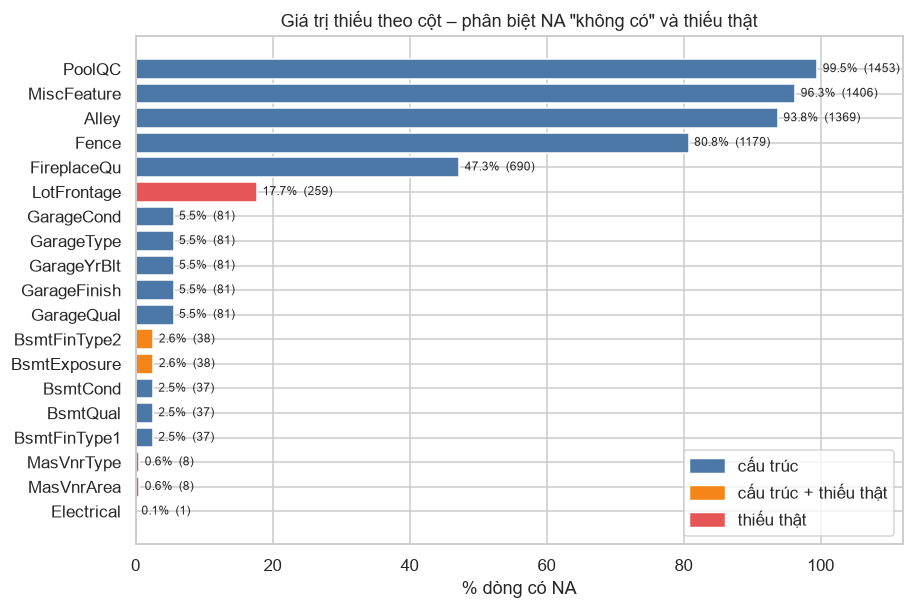

In [6]:
colors = {'cấu trúc': '#4C78A8', 'cấu trúc + thiếu thật': '#F58518', 'thiếu thật': '#E45756'}
d = miss.join(cls.phan_loai)
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(d.index[::-1], d.pct[::-1], color=[colors[k] for k in d.phan_loai[::-1]])
for i, (p, k) in enumerate(zip(d.pct[::-1], d.n_missing[::-1])):
    ax.text(p + 0.8, i, f'{p:.1f}%  ({k})', va='center', fontsize=8)
ax.set_xlim(0, 112); ax.set_xlabel('% dòng có NA')
ax.set_title('Giá trị thiếu theo cột – phân biệt NA "không có" và thiếu thật')
ax.legend(handles=[plt.Rectangle((0,0),1,1,color=v) for v in colors.values()], labels=colors.keys(), loc='lower right')
save('fig01_missing_bar')

### Mẫu thiếu theo dòng – các cột thiếu cùng nhau (Garage*, Bsmt*, MasVnr*)

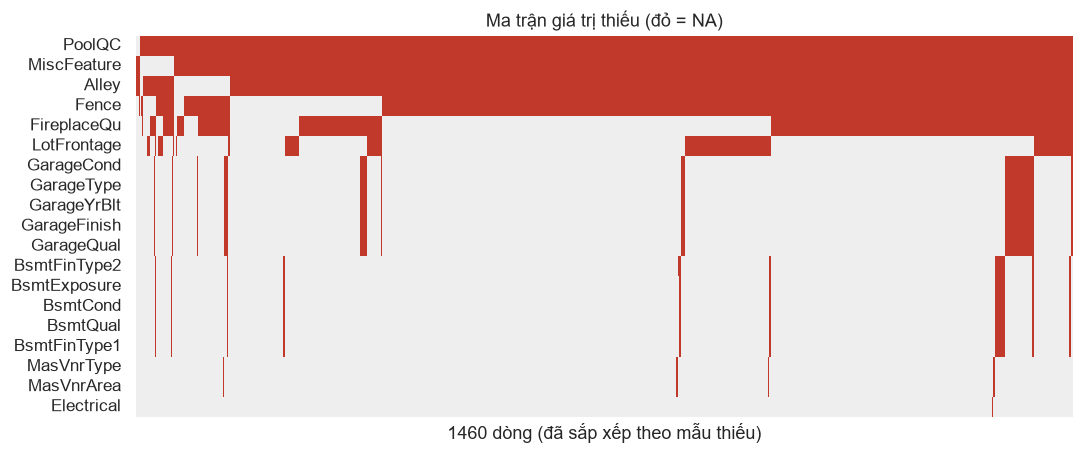

In [7]:
cols = list(miss.index)
M = pd.concat([is_na(c) for c in cols], axis=1); M.columns = cols
M = M.sort_values(by=cols).reset_index(drop=True)
fig, ax = plt.subplots(figsize=(11, 4.5))
sns.heatmap(M.T, cmap=['#EEEEEE', '#C0392B'], cbar=False, xticklabels=False, ax=ax)
ax.set_xlabel(f'{n} dòng (đã sắp xếp theo mẫu thiếu)'); ax.set_title('Ma trận giá trị thiếu (đỏ = NA)')
save('fig02_missing_matrix')

## 3.4 `LotFrontage` – thiếu thật duy nhất ở quy mô lớn (17.7%)
Câu hỏi: thiếu **ngẫu nhiên** hay có quy luật? Nếu có quy luật (theo khu phố, hình dạng lô đất) thì nên điền theo nhóm thay vì điền một số chung.

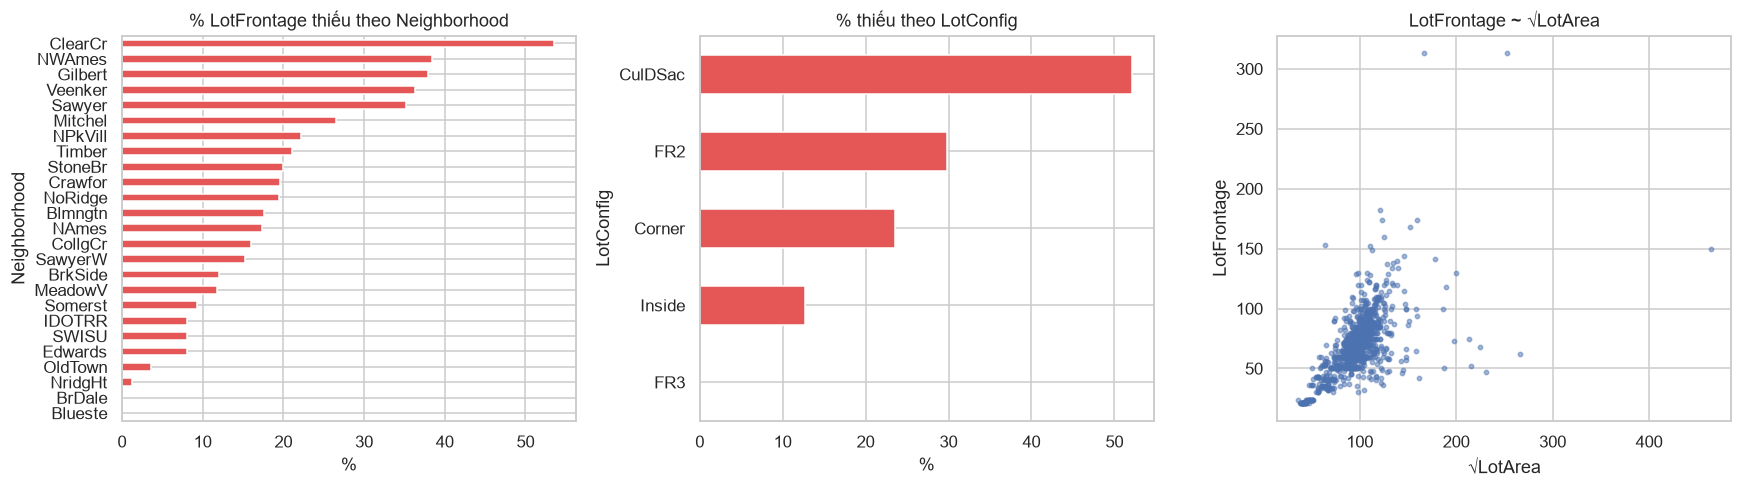

Trung vị LotArea – dòng thiếu LotFrontage: 10624.0 | dòng có: 9262.0
Mann-Whitney p-value (LotArea thiếu vs không thiếu): 4.788735971529332e-07
Tương quan LotFrontage ~ √LotArea: 0.602
Chi-square LotConfig x thiếu: p = 5.491008644163505e-22


In [8]:
lf = raw.LotFrontage.isna()
fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))
by_n = raw.groupby('Neighborhood').LotFrontage.apply(lambda s: s.isna().mean()*100).sort_values()
by_n.plot.barh(ax=ax[0], color='#E45756'); ax[0].set_title('% LotFrontage thiếu theo Neighborhood'); ax[0].set_xlabel('%')
by_c = raw.groupby('LotConfig').LotFrontage.apply(lambda s: s.isna().mean()*100).sort_values()
by_c.plot.barh(ax=ax[1], color='#E45756'); ax[1].set_title('% thiếu theo LotConfig'); ax[1].set_xlabel('%')
ok = ~lf
ax[2].scatter(np.sqrt(raw.LotArea[ok]), raw.LotFrontage[ok], s=8, alpha=.5)
ax[2].set_xlabel('√LotArea'); ax[2].set_ylabel('LotFrontage'); ax[2].set_title('LotFrontage ~ √LotArea')
plt.tight_layout(); save('fig03_lotfrontage')

print('Trung vị LotArea – dòng thiếu LotFrontage:', raw.LotArea[lf].median(), '| dòng có:', raw.LotArea[~lf].median())
print('Mann-Whitney p-value (LotArea thiếu vs không thiếu):', stats.mannwhitneyu(raw.LotArea[lf], raw.LotArea[~lf]).pvalue)
print('Tương quan LotFrontage ~ √LotArea:', round(raw.LotFrontage.corr(np.sqrt(raw.LotArea)), 3))
print('Chi-square LotConfig x thiếu: p =', stats.chi2_contingency(pd.crosstab(raw.LotConfig, lf))[1])

**Thử nghiệm chiến lược điền** – giấu ngẫu nhiên 20% giá trị đã biết, điền lại bằng từng cách, đo MAE (lặp 30 lần):

In [9]:
rng = np.random.default_rng(42)
known = raw[~lf][['LotFrontage', 'LotArea', 'Neighborhood']].copy(); known['sq'] = np.sqrt(known.LotArea)
res = {'Trung vị toàn cục': [], 'Trung vị theo Neighborhood': [], 'Hồi quy theo √LotArea': [], 'Trung vị Neighborhood × LotConfig': []}
known['LotConfig'] = raw.LotConfig[~lf]
for _ in range(30):
    idx = rng.choice(known.index, int(.2*len(known)), replace=False)
    te, tr = known.loc[idx], known.drop(idx)
    res['Trung vị toàn cục'].append((te.LotFrontage - tr.LotFrontage.median()).abs().mean())
    nm = tr.groupby('Neighborhood').LotFrontage.median()
    res['Trung vị theo Neighborhood'].append((te.LotFrontage - te.Neighborhood.map(nm).fillna(tr.LotFrontage.median())).abs().mean())
    b = np.polyfit(tr.sq, tr.LotFrontage, 1)
    res['Hồi quy theo √LotArea'].append((te.LotFrontage - np.polyval(b, te.sq)).abs().mean())
    nc = tr.groupby(['Neighborhood','LotConfig']).LotFrontage.median()
    pred = [nc.get((a, c), nm.get(a, tr.LotFrontage.median())) for a, c in zip(te.Neighborhood, te.LotConfig)]
    res['Trung vị Neighborhood × LotConfig'].append((te.LotFrontage - np.array(pred)).abs().mean())
imp = pd.Series({k: np.mean(v) for k, v in res.items()}, name='MAE').round(2).sort_values()
display(imp.to_frame())

,MAE
Trung vị Neighborhood × LotConfig,12.35
Hồi quy theo √LotArea,12.47
Trung vị theo Neighborhood,12.94
Trung vị toàn cục,16.43


## 3.5 Các giá trị thiếu thật còn lại (số lượng nhỏ)

In [10]:
print('MasVnrType & MasVnrArea thiếu CÙNG dòng:', bool((is_na('MasVnrType') == is_na('MasVnrArea')).all()), '| số dòng:', int(is_na('MasVnrType').sum()))
display(raw.loc[is_na('MasVnrType') | is_na('Electrical'),
                ['Id','MasVnrType','MasVnrArea','Electrical','YearBuilt','Neighborhood','SalePrice']])
print('Hai ô thiếu "lẻ" trong nhóm hầm (thực chất có hầm nhưng thiếu 1 thuộc tính):')
display(raw.loc[raw.Id.isin([949, 333]), ['Id','TotalBsmtSF','BsmtQual','BsmtCond','BsmtExposure','BsmtFinType1','BsmtFinType2']])
print('Mode của Electrical:', raw.Electrical[raw.Electrical != 'NA'].mode()[0])

MasVnrType & MasVnrArea thiếu CÙNG dòng: True | số dòng: 8


,Id,MasVnrType,MasVnrArea,Electrical,YearBuilt,Neighborhood,SalePrice
234,235,NA,NaN,SBrkr,2002,Gilbert,216500
529,530,NA,NaN,SBrkr,1957,Crawfor,200624
650,651,NA,NaN,SBrkr,2007,Somerst,205950
936,937,NA,NaN,SBrkr,2003,SawyerW,184900
973,974,NA,NaN,SBrkr,2007,Somerst,182000
977,978,NA,NaN,SBrkr,2006,Somerst,199900
1243,1244,NA,NaN,SBrkr,2006,NridgHt,465000
1278,1279,NA,NaN,SBrkr,2002,CollgCr,237000
1379,1380,None,0.0,NA,2006,Timber,167500


Hai ô thiếu "lẻ" trong nhóm hầm (thực chất có hầm nhưng thiếu 1 thuộc tính):


,Id,TotalBsmtSF,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinType2
332,333,3206,Gd,TA,No,GLQ,NA
948,949,936,Gd,TA,NA,Unf,Unf


Mode của Electrical: SBrkr


## 3.6 Mẫu bất thường: kiểm tra tính nhất quán logic
Mỗi quy tắc dưới đây dựa trên ràng buộc "phải đúng" giữa các biến (ví dụ: tổng diện tích các tầng = `GrLivArea`). Dòng vi phạm là **mẫu bất thường** cần xem xét, độc lập với việc giá trị có "lớn/nhỏ" hay không.

In [11]:
r = raw
rules = [
 # (tên quy tắc, mức độ nếu vi phạm, điều kiện vi phạm)
 ('Bán trước khi tu sửa xong (YrSold < YearRemodAdd)',        'Lỗi logic',   r.YrSold < r.YearRemodAdd),
 ('Bán trước khi xây (YrSold < YearBuilt)',                    'Lỗi logic',   r.YrSold < r.YearBuilt),
 ('Tu sửa trước khi xây (YearRemodAdd < YearBuilt)',           'Lỗi logic',   r.YearRemodAdd < r.YearBuilt),
 ('Garage xây sau năm bán (GarageYrBlt > YrSold)',             'Lỗi logic',   r.GarageYrBlt > r.YrSold),
 ('Garage xây trước nhà (GarageYrBlt < YearBuilt)',            'Đáng ngờ',    r.GarageYrBlt < r.YearBuilt),
 ('Tổng tầng ≠ GrLivArea (1st+2nd+LowQual)',                   'Lỗi logic',   (r['1stFlrSF']+r['2ndFlrSF']+r.LowQualFinSF) != r.GrLivArea),
 ('Tổng diện tích hầm ≠ TotalBsmtSF',                          'Lỗi logic',   (r.BsmtFinSF1+r.BsmtFinSF2+r.BsmtUnfSF) != r.TotalBsmtSF),
 ('Có phòng tắm hầm nhưng TotalBsmtSF = 0',                    'Lỗi logic',   ((r.BsmtFullBath+r.BsmtHalfBath) > 0) & (r.TotalBsmtSF == 0)),
 ('GarageCars và GarageArea mâu thuẫn (một cái = 0)',          'Lỗi logic',   ((r.GarageCars==0)&(r.GarageArea>0)) | ((r.GarageCars>0)&(r.GarageArea==0))),
 ('PoolArea và PoolQC mâu thuẫn',                              'Lỗi logic',   ((r.PoolArea>0)&is_na('PoolQC')) | ((r.PoolArea==0)&~is_na('PoolQC'))),
 ('Fireplaces và FireplaceQu mâu thuẫn',                       'Lỗi logic',   ((r.Fireplaces>0)&is_na('FireplaceQu')) | ((r.Fireplaces==0)&~is_na('FireplaceQu'))),
 ('MasVnrType="None" nhưng MasVnrArea>0 (hoặc ngược lại)',     'Lỗi nhập liệu', ((r.MasVnrType=='None')&(r.MasVnrArea>0)) | (~r.MasVnrType.isin(['None','NA'])&(r.MasVnrArea==0))),
 ('MiscFeature có nhưng MiscVal = 0',                          'Đáng ngờ',    (r.MiscVal==0) & ~is_na('MiscFeature')),
 ('Nhà "1Story" nhưng có diện tích tầng 2',                    'Đáng ngờ',    (r.HouseStyle=='1Story') & (r['2ndFlrSF']>0)),
 ('Hầm lớn hơn tầng 1 (TotalBsmtSF > 1stFlrSF)',               'Hiếm',        r.TotalBsmtSF > r['1stFlrSF']),
 ('0 phòng ngủ trên mặt đất (BedroomAbvGr = 0)',               'Hiếm',        r.BedroomAbvGr == 0),
 ('0 phòng tắm đầy đủ (FullBath = 0)',                         'Hiếm',        r.FullBath == 0),
 ('Số bếp ≠ 1 (KitchenAbvGr ≠ 1)',                             'Hiếm',        r.KitchenAbvGr != 1),
 ('Dòng trùng lặp (trừ Id)',                                   'Lỗi logic',   r.drop(columns='Id').duplicated()),
 ('Id trùng',                                                  'Lỗi logic',   r.Id.duplicated()),
]
audit = pd.DataFrame([[nm, lv, int(v.sum()), r.Id[v].tolist()[:8]] for nm, lv, v in rules],
                     columns=['quy_tac', 'muc_do', 'so_dong_vi_pham', 'Id_vi_pham (tối đa 8)'])
audit['ket_qua'] = np.where(audit.so_dong_vi_pham == 0, 'Đạt', audit.muc_do)
display(audit.sort_values('so_dong_vi_pham', ascending=False).reset_index(drop=True))
print('Số quy tắc đạt hoàn toàn:', (audit.so_dong_vi_pham == 0).sum(), '/', len(audit))

,quy_tac,muc_do,so_dong_vi_pham,Id_vi_pham (tối đa 8),ket_qua
0,Số bếp ≠ 1 (KitchenAbvGr ≠ 1),Hiếm,68,"[9, 10, 18, 40, 49, 75, 79, 94]",Hiếm
1,Hầm lớn hơn tầng 1 (TotalBsmtSF > 1stFlrSF),Hiếm,35,"[42, 127, 154, 247, 270, 272, 280, 314]",Hiếm
2,0 phòng tắm đầy đủ (FullBath = 0),Hiếm,9,"[54, 189, 376, 598, 635, 917, 1164, 1214]",Hiếm
3,Garage xây trước nhà (GarageYrBlt < YearBuilt),Đáng ngờ,9,"[30, 94, 325, 601, 737, 1104, 1377, 1415]",Đáng ngờ
4,"MasVnrType=""None"" nhưng MasVnrArea>0 (hoặc ngư...",Lỗi nhập liệu,7,"[625, 689, 774, 1231, 1242, 1301, 1335]",Lỗi nhập liệu
5,0 phòng ngủ trên mặt đất (BedroomAbvGr = 0),Hiếm,6,"[54, 190, 635, 1164, 1214, 1271]",Hiếm
6,"Nhà ""1Story"" nhưng có diện tích tầng 2",Đáng ngờ,2,"[165, 1271]",Đáng ngờ
7,MiscFeature có nhưng MiscVal = 0,Đáng ngờ,2,"[874, 1201]",Đáng ngờ
8,Bán trước khi tu sửa xong (YrSold < YearRemodAdd),Lỗi logic,1,[524],Lỗi logic
9,Garage xây sau năm bán (GarageYrBlt > YrSold),Lỗi logic,0,[],Đạt


Số quy tắc đạt hoàn toàn: 11 / 20


### Điều kiện bán (`SaleCondition`) và biến gần như hằng số

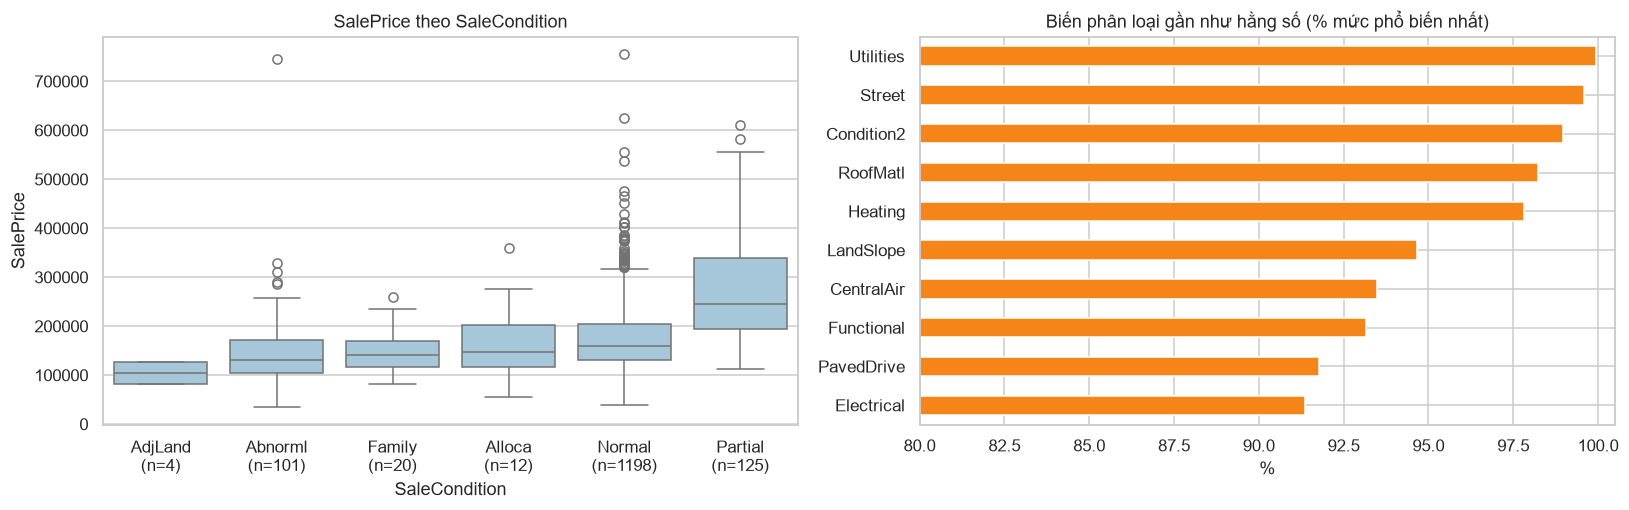

{'Normal': 82.1, 'Partial': 8.6, 'Abnorml': 6.9, 'Family': 1.4, 'Alloca': 0.8, 'AdjLand': 0.3}
Biến có 1 mức chiếm ≥ 95%: {'Utilities': 99.93, 'Street': 99.59, 'Condition2': 98.97, 'RoofMatl': 98.22, 'Heating': 97.81}


In [12]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.8))
order = raw.groupby('SaleCondition').SalePrice.median().sort_values().index
sns.boxplot(data=raw, x='SaleCondition', y='SalePrice', order=order, ax=ax[0], color='#9ecae1')
cnt = raw.SaleCondition.value_counts()
ax[0].set_xticklabels([f'{o}\n(n={cnt[o]})' for o in order]); ax[0].set_title('SalePrice theo SaleCondition')

catc = [c for c in raw.columns if not pd.api.types.is_numeric_dtype(raw[c]) and c not in none_cond and c not in no_proxy]
dom = pd.Series({c: raw[c].value_counts(normalize=True).iloc[0]*100 for c in catc}).sort_values(ascending=False).head(10)
dom.iloc[::-1].plot.barh(ax=ax[1], color='#F58518'); ax[1].set_xlim(80, 100.5)
ax[1].set_title('Biến phân loại gần như hằng số (% mức phổ biến nhất)'); ax[1].set_xlabel('%')
plt.tight_layout(); save('fig04_salecondition_nearconstant')
print((raw.SaleCondition.value_counts(normalize=True)*100).round(1).to_dict())
print('Biến có 1 mức chiếm ≥ 95%:', dom[dom >= 95].round(2).to_dict())

## 3.7 Kết luận Phần 3 và chiến lược xử lý
| Nhóm | Cột | Bản chất | Xử lý đề xuất |
|---|---|---|---|
| NA cấu trúc (= không có) | PoolQC, MiscFeature, Alley, Fence, FireplaceQu, Garage\*, Bsmt\* | Không phải thiếu; đã kiểm chứng bằng biến đối chứng (PoolArea, Fireplaces, GarageArea, TotalBsmtSF) | Thay `NA` bằng mức `"None"`; riêng `GarageYrBlt` (số) điền `0` hoặc `YearBuilt` + cờ `HasGarage` |
| Thiếu thật, quy mô lớn | LotFrontage (17.7%) | Có quy luật theo Neighborhood/LotConfig (không hoàn toàn ngẫu nhiên) | Điền trung vị theo Neighborhood × LotConfig (dự phòng: theo Neighborhood) – MAE ≈ 12.4 so với 16.4 của trung vị toàn cục (giảm ~25%, xem 3.4); cân nhắc thêm cờ `LotFrontage_missing` |
| Thiếu thật, nhỏ | MasVnrType/MasVnrArea (8), Electrical (1), BsmtExposure (Id 949), BsmtFinType2 (Id 333) | Thiếu ngẫu nhiên, rất ít | Điền mode (hoặc `None`/0 với MasVnr) |
| Bất thường logic | Id 524 (bán trước khi tu sửa), MasVnr None nhưng có diện tích, Garage xây trước nhà… | Lỗi/nhập liệu hoặc nghiệp vụ đặc biệt | Ghi nhận; Id 524 loại ở Phần 4 |
| Biến gần hằng | Utilities, Street, Condition2, RoofMatl… | Gần như không phân biệt được các nhà | Cân nhắc bỏ khi chọn đặc trưng |
| Điều kiện bán | SaleCondition ≠ Normal (~18%) | `Partial` giá cao hơn, `Abnorml` thấp hơn rõ rệt (khớp nhận xét của paper) | Giữ làm biến giải thích; nếu cần mô hình "giá thị trường" thì lọc `Normal` |

# PHẦN 4 – Giá trị ngoại lệ (outlier)

Quy trình 3 tầng: **đơn biến** (IQR, z-score) → **hai biến** (scatter với SalePrice) → **đa biến** (Cook's distance, studentized residual, Isolation Forest).  
Nguyên tắc: *ngoại lệ thống kê ≠ ngoại lệ cần loại*. Chỉ loại khi có bằng chứng là lỗi hoặc không đại diện cho thị trường.

## 4.1 Biến mục tiêu `SalePrice`

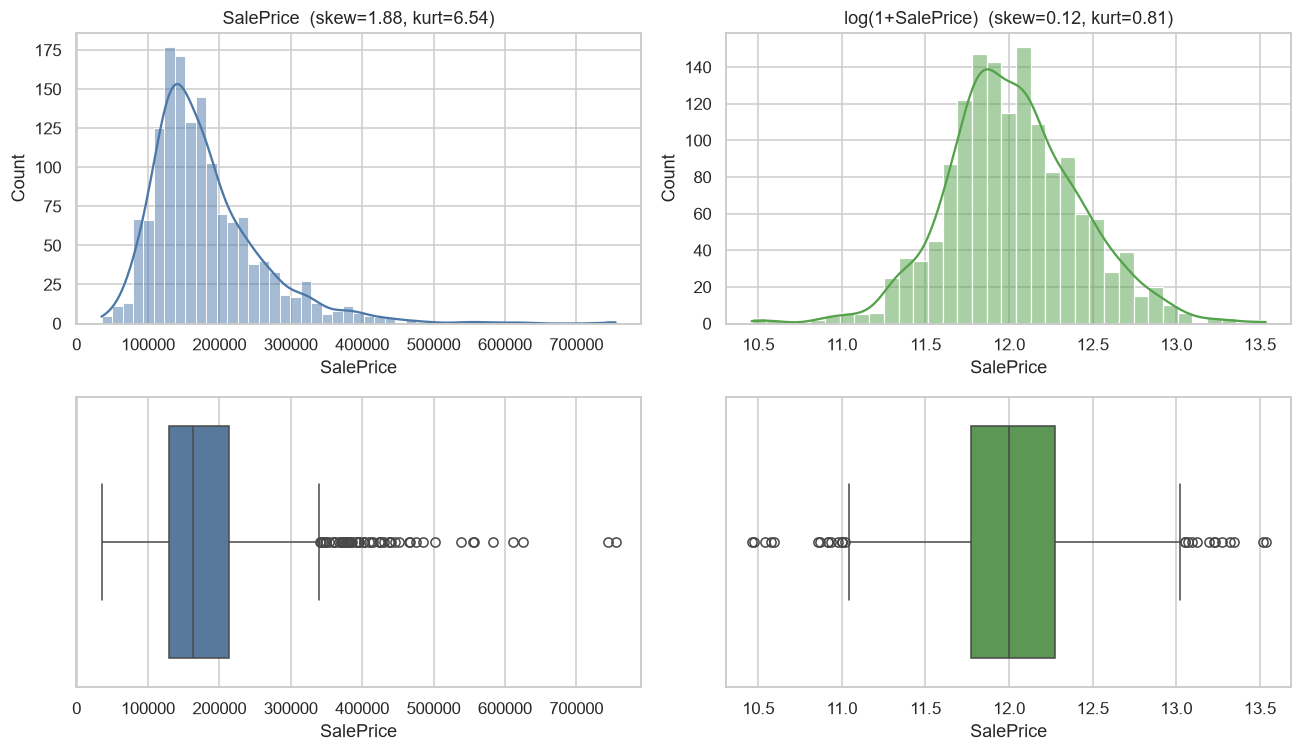

Rào IQR: [3,938 ; 340,038]  -> 61 điểm (chỉ phía trên: giá cao)
z-score > 3: 22 | sau log, IQR: 28


In [13]:
y = raw.SalePrice
fig, ax = plt.subplots(2, 2, figsize=(12, 7))
sns.histplot(y, kde=True, ax=ax[0,0], color='#4C78A8'); ax[0,0].set_title(f'SalePrice  (skew={y.skew():.2f}, kurt={y.kurt():.2f})')
sns.histplot(np.log1p(y), kde=True, ax=ax[0,1], color='#54A24B'); ax[0,1].set_title(f'log(1+SalePrice)  (skew={np.log1p(y).skew():.2f}, kurt={np.log1p(y).kurt():.2f})')
sns.boxplot(x=y, ax=ax[1,0], color='#4C78A8'); sns.boxplot(x=np.log1p(y), ax=ax[1,1], color='#54A24B')
plt.tight_layout(); save('fig05_saleprice')
q1, q3 = y.quantile([.25, .75]); iqr = q3 - q1
print(f'Rào IQR: [{q1-1.5*iqr:,.0f} ; {q3+1.5*iqr:,.0f}]  -> {int(((y<q1-1.5*iqr)|(y>q3+1.5*iqr)).sum())} điểm (chỉ phía trên: giá cao)')
print('z-score > 3:', int((np.abs(stats.zscore(y)) > 3).sum()), '| sau log, IQR:', int(((np.log1p(y) < np.log1p(y).quantile(.25) - 1.5*stats.iqr(np.log1p(y))) | (np.log1p(y) > np.log1p(y).quantile(.75) + 1.5*stats.iqr(np.log1p(y)))).sum()))

## 4.2 Ngoại lệ đơn biến trên 19 biến liên tục (IQR & z-score)

In [14]:
cont = ['LotFrontage','LotArea','MasVnrArea','BsmtFinSF1','BsmtFinSF2','BsmtUnfSF','TotalBsmtSF','1stFlrSF','2ndFlrSF',
        'LowQualFinSF','GrLivArea','GarageArea','WoodDeckSF','OpenPorchSF','EnclosedPorch','3SsnPorch','ScreenPorch','PoolArea','MiscVal']
def fences(s, k):
    q1, q3 = s.quantile([.25, .75]); i = q3 - q1; return q1 - k*i, q3 + k*i
rows = []
for c in cont:
    s = raw[c].dropna()
    lo, hi = fences(s, 1.5); lo3, hi3 = fences(s, 3)
    rows.append([c, int(((s<lo)|(s>hi)).sum()), int(((s<lo3)|(s>hi3)).sum()), int((np.abs(stats.zscore(s))>3).sum()),
                 round((s==0).mean()*100,1), round(s.skew(),2), round(hi,0), s.max()])
uni = pd.DataFrame(rows, columns=['bien','IQR_1.5','IQR_3 (cực đoan)','z>3','%_bang_0','skew','rao_tren_IQR','max']).set_index('bien')
display(uni.sort_values('IQR_1.5', ascending=False))

,IQR_1.5,IQR_3 (cực đoan),z>3,%_bang_0,skew,rao_tren_IQR,max
bien,,,,,,,
EnclosedPorch,208,208,51,85.8,3.09,0.0,552.0
BsmtFinSF2,167,167,50,88.6,4.26,0.0,1474.0
ScreenPorch,116,116,55,92.1,4.12,0.0,480.0
MasVnrArea,96,25,32,59.3,2.67,415.0,1600.0
LotFrontage,88,12,12,0.0,2.16,112.0,313.0
OpenPorchSF,77,18,27,44.9,2.36,170.0,547.0
LotArea,69,34,13,0.0,12.21,17674.0,215245.0
TotalBsmtSF,61,5,10,2.5,1.52,2052.0,6110.0
MiscVal,52,52,8,96.4,24.48,0.0,15500.0


> **Lưu ý khi đọc bảng:** các biến "zero-inflated" (các loại porch, `PoolArea`, `MiscVal`, `BsmtFinSF2`, `LowQualFinSF`…) có >85% giá trị bằng 0 nên IQR = 0 và coi *mọi giá trị khác 0* là ngoại lệ (đó cũng là lý do cột `IQR_3` trùng `IQR_1.5` ở các biến này). Đây là hạn chế của IQR, **không phải lỗi dữ liệu**; những biến này nên được xử lý bằng cờ nhị phân (có/không) thay vì loại điểm.

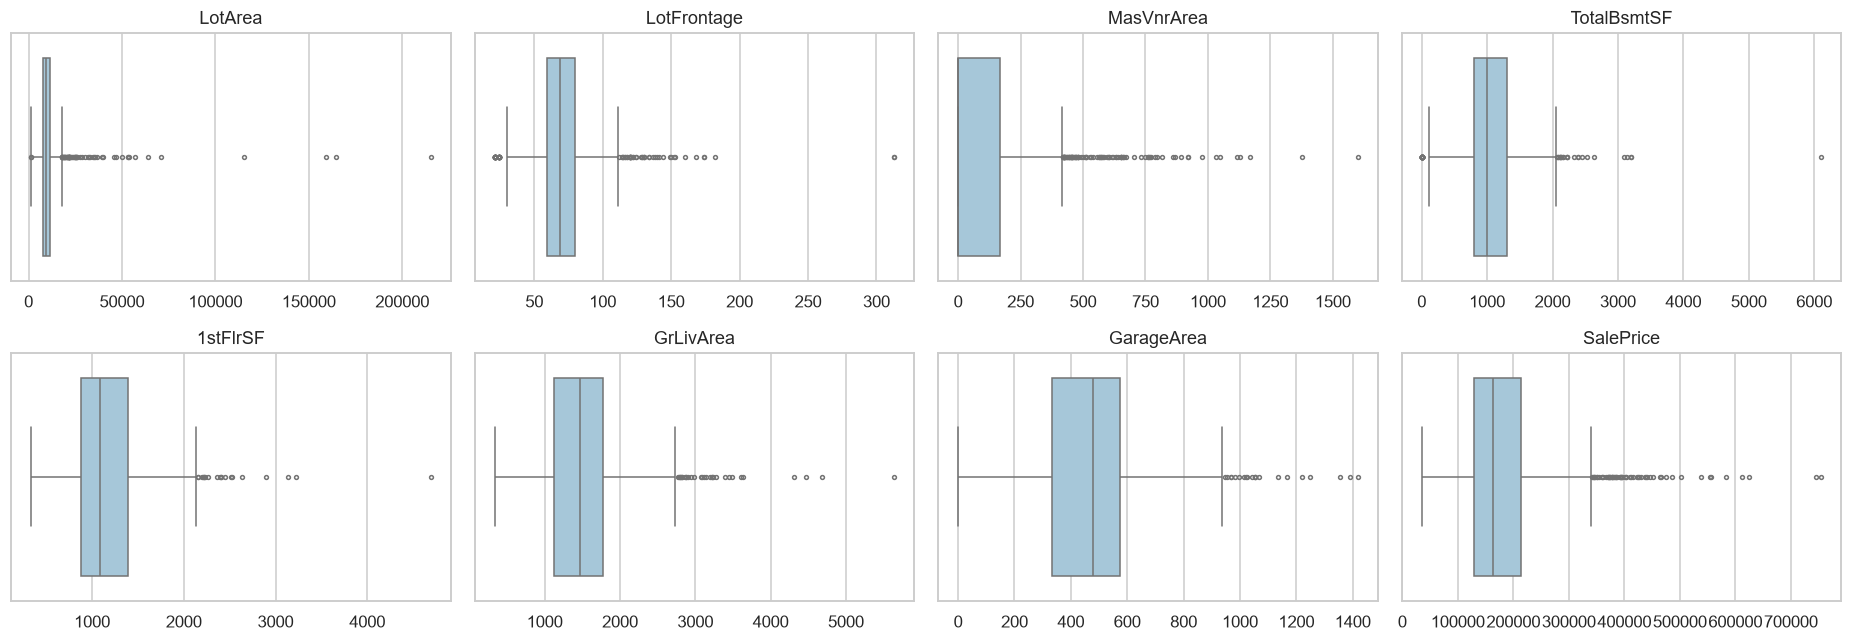

In [15]:
show = ['LotArea','LotFrontage','MasVnrArea','TotalBsmtSF','1stFlrSF','GrLivArea','GarageArea','SalePrice']
fig, axes = plt.subplots(2, 4, figsize=(17, 6))
for a, c in zip(axes.ravel(), show):
    sns.boxplot(x=raw[c], ax=a, color='#9ecae1', fliersize=2.5); a.set_title(c); a.set_xlabel('')
plt.tight_layout(); save('fig06_boxplots')

## 4.3 Ngoại lệ hai biến: quan hệ với `SalePrice`

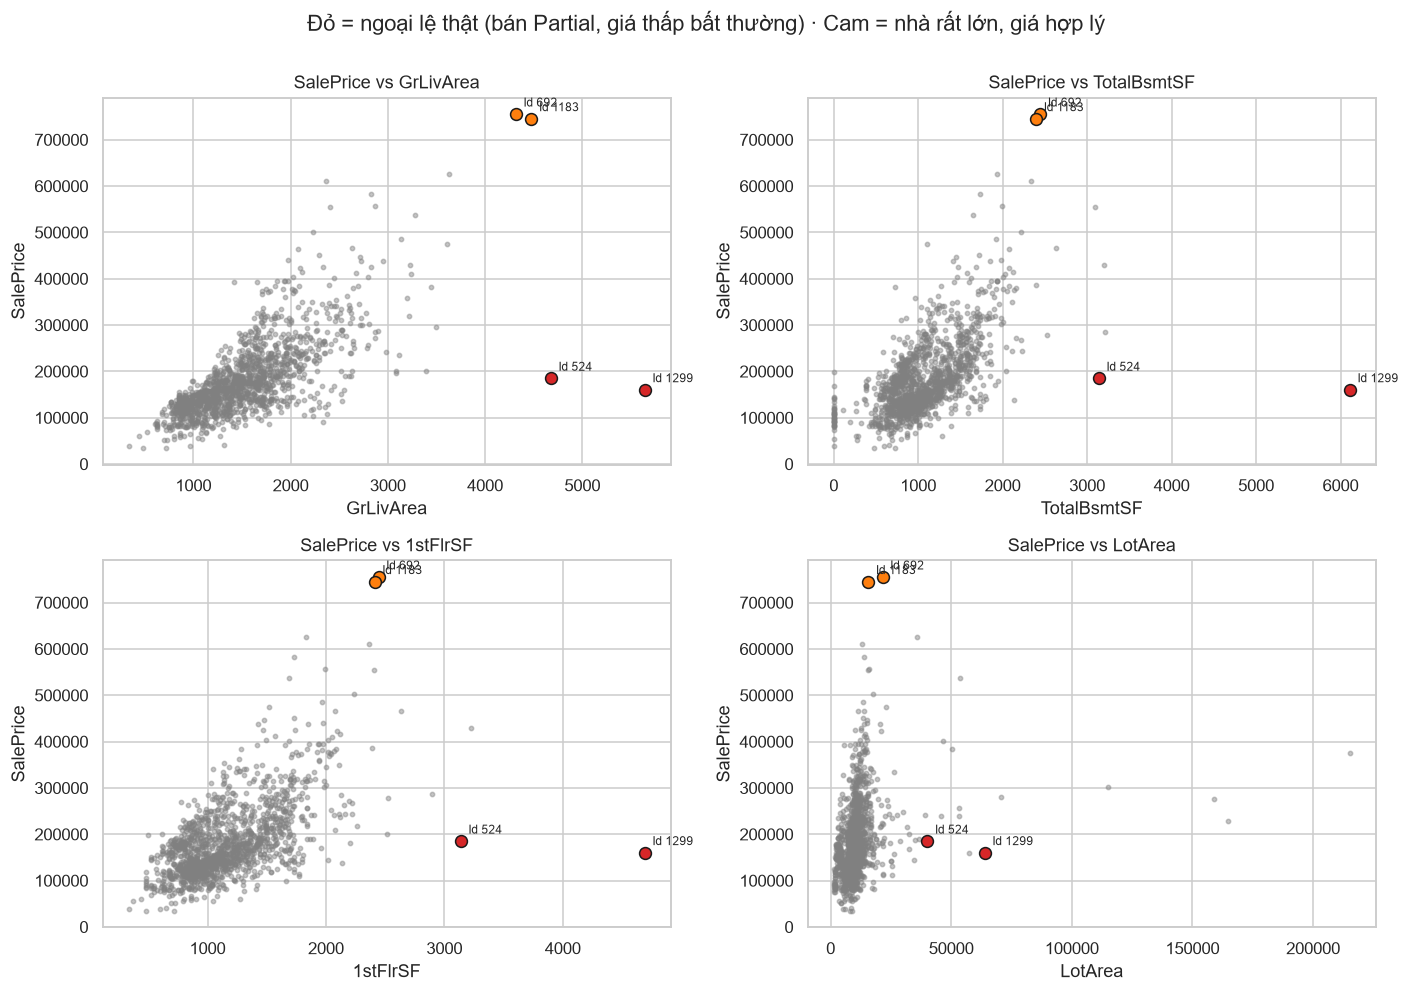

,Id,GrLivArea,TotalBsmtSF,LotArea,OverallQual,Neighborhood,SaleCondition,SalePrice
523,524,4676,3138,40094,10,Edwards,Partial,184750
691,692,4316,2444,21535,10,NoRidge,Normal,755000
1182,1183,4476,2396,15623,10,NoRidge,Abnorml,745000
1298,1299,5642,6110,63887,10,Edwards,Partial,160000


In [16]:
key = {524: ('#D62728', 'Id 524'), 1299: ('#D62728', 'Id 1299'), 692: ('#FF7F0E', 'Id 692'), 1183: ('#FF7F0E', 'Id 1183')}
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for a, c in zip(axes.ravel(), ['GrLivArea', 'TotalBsmtSF', '1stFlrSF', 'LotArea']):
    a.scatter(raw[c], raw.SalePrice, s=8, alpha=.45, color='gray')
    for i, (col, lab) in key.items():
        row = raw[raw.Id == i].iloc[0]
        a.scatter(row[c], row.SalePrice, s=60, color=col, edgecolor='k', zorder=3)
        a.annotate(lab, (row[c], row.SalePrice), textcoords='offset points', xytext=(5, 5), fontsize=8)
    a.set_xlabel(c); a.set_ylabel('SalePrice'); a.set_title(f'SalePrice vs {c}')
plt.suptitle('Đỏ = ngoại lệ thật (bán Partial, giá thấp bất thường) · Cam = nhà rất lớn, giá hợp lý', y=1.0)
plt.tight_layout(); save('fig07_scatter_outliers')
display(raw.loc[raw.GrLivArea > 4000, ['Id','GrLivArea','TotalBsmtSF','LotArea','OverallQual','Neighborhood','SaleCondition','SalePrice']])

## 4.4 Ngoại lệ đa biến
Một điểm có thể không lạ ở từng biến riêng lẻ nhưng lạ khi xét **tổ hợp** (nhà chất lượng 10/10, diện tích khổng lồ nhưng giá chỉ 160k). Dùng 3 góc nhìn:
- **Studentized residual**: mô hình dự đoán sai nhiều đến đâu (|r| > 3).
- **Cook's distance**: điểm đó *kéo lệch* đường hồi quy bao nhiêu (ngưỡng thường dùng 4/n).
- **Isolation Forest**: không giám sát, bắt điểm "dễ bị cô lập" trong không gian đặc trưng.

OLS log(SalePrice) ~ ['GrLivArea', 'TotalBsmtSF', 'OverallQual', 'GarageCars', 'YearBuilt']:  R² = 0.812


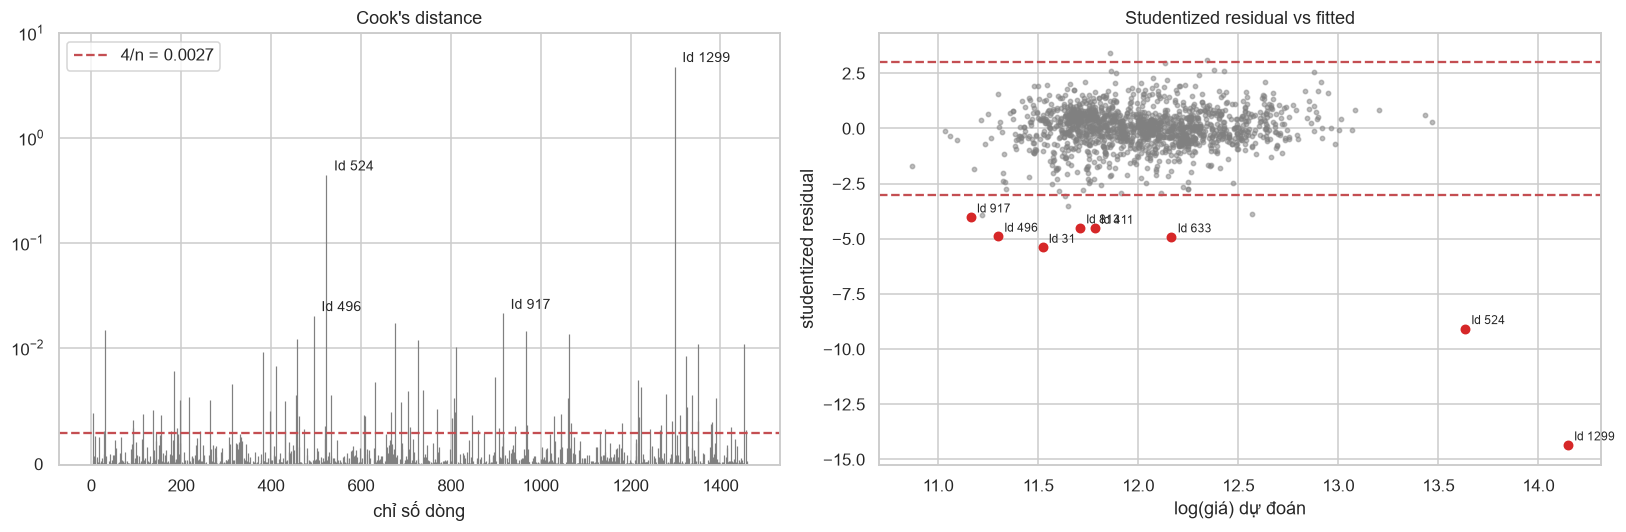

{'f_paper(GrLivArea>4000)': 4, 'f_rstud>3': 14, 'f_cook>4/n': 82, 'f_iso': 15}


,Id,GrLivArea,OverallQual,SaleCondition,SalePrice,fitted_price,cook,rstud,so_phuong_phap,f_paper(GrLivArea>4000),f_rstud>3,f_cook>4/n,f_iso
1298,1299,5642,10,Partial,160000,1393581.0,4.794,-14.344,4,True,True,True,True
523,524,4676,10,Partial,184750,833663.0,0.445,-9.073,4,True,True,True,True
916,917,480,2,Abnorml,35311,70441.0,0.021,-4.016,2,False,True,True,False
495,496,720,4,Abnorml,34900,80772.0,0.020,-4.886,2,False,True,True,False
30,31,1317,4,Normal,40000,100876.0,0.015,-5.390,2,False,True,True,False
968,969,968,3,Abnorml,37900,74428.0,0.014,-3.919,2,False,True,True,False
457,458,1663,4,Normal,256000,141640.0,0.012,3.434,2,False,True,True,False
812,813,1044,5,Alloca,55993,121638.0,0.010,-4.507,2,False,True,True,False
1324,1325,1795,8,Partial,147000,287223.0,0.009,-3.886,2,False,True,True,False
410,411,1276,5,Abnorml,60000,130858.0,0.008,-4.529,2,False,True,True,False


In [17]:
feat = ['GrLivArea', 'TotalBsmtSF', 'OverallQual', 'GarageCars', 'YearBuilt']
X = sm.add_constant(naive[feat]); yl = np.log(naive.SalePrice)
ols = sm.OLS(yl, X).fit(); infl = ols.get_influence()
d = naive[['Id','GrLivArea','TotalBsmtSF','OverallQual','SaleCondition','SalePrice']].copy()
d['cook'] = infl.cooks_distance[0]; d['rstud'] = infl.resid_studentized_external
d['fitted_price'] = np.exp(ols.fittedvalues).round(0)
print(f'OLS log(SalePrice) ~ {feat}:  R² = {ols.rsquared:.3f}')
thr = 4 / len(d)

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
ax[0].vlines(d.index, 0, d.cook, color='gray', lw=.8); ax[0].axhline(thr, color='r', ls='--', label=f'4/n = {thr:.4f}')
for _, rw in d.nlargest(4, 'cook').iterrows():
    ax[0].annotate(f"Id {int(rw.Id)}", (rw.name, rw.cook), textcoords='offset points', xytext=(5, 3), fontsize=9)
ax[0].set_yscale('symlog', linthresh=.01); ax[0].set_ylim(0, 10); ax[0].set_title("Cook's distance"); ax[0].set_xlabel('chỉ số dòng'); ax[0].legend()
ax[1].scatter(ols.fittedvalues, d.rstud, s=8, alpha=.5, color='gray')
for v in (-3, 3): ax[1].axhline(v, color='r', ls='--')
big = d[np.abs(d.rstud) > 4]
ax[1].scatter(ols.fittedvalues[big.index], big.rstud, color='#D62728', s=30)
for i, rw in big.iterrows(): ax[1].annotate(f"Id {int(rw.Id)}", (ols.fittedvalues[i], rw.rstud), textcoords='offset points', xytext=(4, 3), fontsize=8)
ax[1].set_xlabel('log(giá) dự đoán'); ax[1].set_ylabel('studentized residual'); ax[1].set_title('Studentized residual vs fitted')
plt.tight_layout(); save('fig08_cook_resid')

iso_cols = ['LotArea','GrLivArea','TotalBsmtSF','1stFlrSF','GarageArea','OverallQual','YearBuilt','SalePrice']
iso = IsolationForest(contamination=0.01, random_state=42).fit(naive[iso_cols])
d['iso'] = iso.predict(naive[iso_cols]) == -1
d['f_paper(GrLivArea>4000)'] = naive.GrLivArea > 4000
d['f_rstud>3'] = np.abs(d.rstud) > 3
d['f_cook>4/n'] = d.cook > thr
d['f_iso'] = d.iso
flags = ['f_paper(GrLivArea>4000)', 'f_rstud>3', 'f_cook>4/n', 'f_iso']
d['so_phuong_phap'] = d[flags].sum(axis=1)
print({f: int(d[f].sum()) for f in flags})
cand = d[d.so_phuong_phap >= 2].sort_values(['so_phuong_phap', 'cook'], ascending=False)
display(cand[['Id','GrLivArea','OverallQual','SaleCondition','SalePrice','fitted_price','cook','rstud','so_phuong_phap'] + flags].round(3))

### Nhóm ngoại lệ giá thấp (|studentized residual| > 3)

In [18]:
low = d[np.abs(d.rstud) > 3].sort_values('rstud')
display(low[['Id','GrLivArea','OverallQual','SaleCondition','SalePrice','fitted_price','rstud']].round(2))
print('Phân bố SaleCondition của nhóm |r|>3:', low.SaleCondition.value_counts().to_dict(),
      '| tỉ lệ Abnorml toàn tập:', f"{(naive.SaleCondition=='Abnorml').mean()*100:.1f}%")

,Id,GrLivArea,OverallQual,SaleCondition,SalePrice,fitted_price,rstud
1298,1299,5642,10,Partial,160000,1393581.0,-14.34
523,524,4676,10,Partial,184750,833663.0,-9.07
30,31,1317,4,Normal,40000,100876.0,-5.39
632,633,1411,7,Family,82500,192187.0,-4.92
495,496,720,4,Abnorml,34900,80772.0,-4.89
410,411,1276,5,Abnorml,60000,130858.0,-4.53
812,813,1044,5,Alloca,55993,121638.0,-4.51
916,917,480,2,Abnorml,35311,70441.0,-4.02
968,969,968,3,Abnorml,37900,74428.0,-3.92
1324,1325,1795,8,Partial,147000,287223.0,-3.89


Phân bố SaleCondition của nhóm |r|>3: {'Abnorml': 5, 'Partial': 4, 'Normal': 3, 'Family': 1, 'Alloca': 1} | tỉ lệ Abnorml toàn tập: 6.9%


## 4.5 Phân loại và quyết định
| Id | Đặc điểm | Chẩn đoán | Quyết định |
|---|---|---|---|
| **1299** | GrLivArea 5642, TotalBsmtSF 6110, OverallQual 10, giá **160,000**, SaleCondition = Partial | Ngoại lệ **thật**: Cook's D ≈ 4.8, rstudent ≈ −14; nhà lớn nhất tập dữ liệu nhưng giá thấp ngang nhà trung bình | **LOẠI** |
| **524** | GrLivArea 4676, OverallQual 10, giá **184,750**, Partial; còn vi phạm quy tắc `YrSold < YearRemodAdd` | Ngoại lệ **thật**: giao dịch Partial (nhà mới chưa hoàn thiện lúc định giá) → giá không phản ánh giá trị thị trường | **LOẠI** |
| 692, 1183 | GrLivArea 4316 / 4476, OverallQual 10, giá 755,000 / 745,000 (khu NoRidge) | Nhà rất lớn nhưng **giá hợp lý**: mô hình dự đoán gần đúng (rstudent ≈ 0.6 và 0.3, Cook's D ≈ 0.001) → là điểm đòn bẩy cao hợp lệ, không phải lỗi | **GIỮ** hoặc loại theo khuyến nghị paper (xem 4.6) |
| 496, 917, 969, 31… | Giá rất thấp so với dự đoán (rstudent < −3); đa số là nhà nhỏ, chất lượng thấp | `Abnorml` (siết nợ, bán gấp) chiếm 5/14 điểm (36%) trong khi chỉ 6.9% toàn tập → giảm giá có thật | **GIỮ** (đã có biến SaleCondition giải thích) |
| 314 (LotArea 215,245), 935/1299 (LotFrontage 313), 298 (MasVnrArea 1600), 347 (MiscVal 15,500) | Ngoại lệ đơn biến rất lớn, giá trị có thật | Không phải lỗi, ảnh hưởng đến phân phối lệch | **GIỮ**, xử lý bằng biến đổi log / winsorize khi mô hình hoá |

## 4.6 Tác động của việc loại ngoại lệ

,n,R² (log giá ~ 5 biến),"corr(GrLivArea, SalePrice)",skew(GrLivArea),skew(TotalBsmtSF)
Giữ nguyên (1460),1460.0,0.8119,0.7086,1.367,1.524
"Loại 2 điểm thật: 524, 1299",1458.0,0.8475,0.7350,1.011,0.512
Loại 4 nhà > 4000 sq ft (theo paper),1456.0,0.8445,0.7205,0.835,0.486


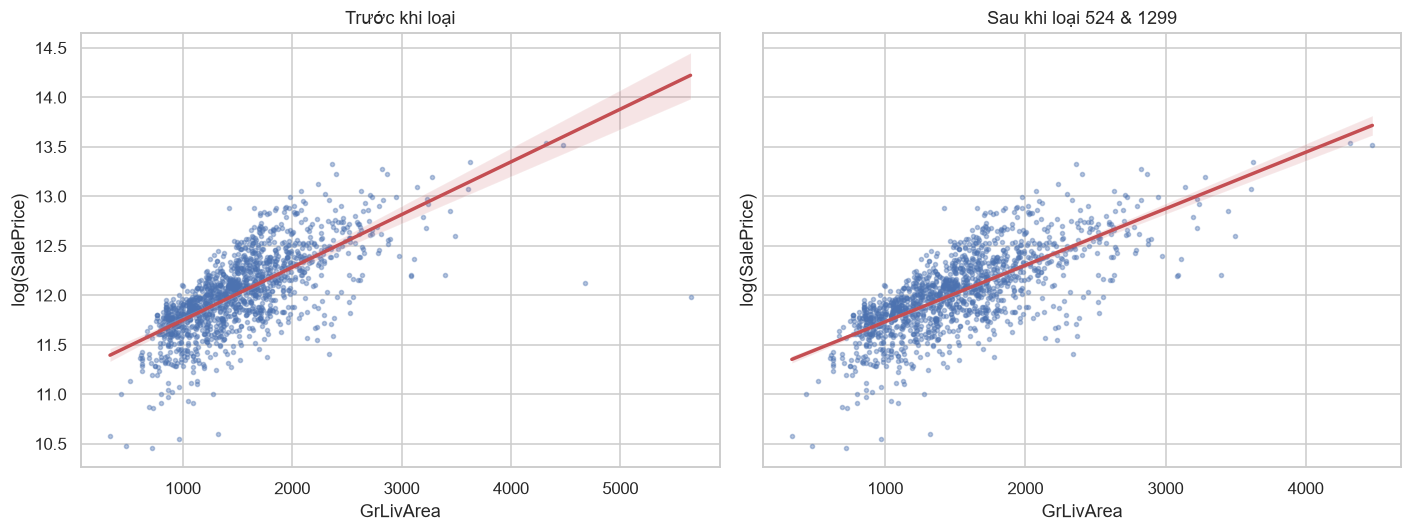

In [19]:
def fit_r2(df_):
    Xs = sm.add_constant(df_[feat]); return sm.OLS(np.log(df_.SalePrice), Xs).fit().rsquared
sc = {'Giữ nguyên (1460)': naive,
      'Loại 2 điểm thật: 524, 1299': naive[~naive.Id.isin([524, 1299])],
      'Loại 4 nhà > 4000 sq ft (theo paper)': naive[naive.GrLivArea <= 4000]}
eff = pd.DataFrame({k: {'n': len(v), 'R² (log giá ~ 5 biến)': round(fit_r2(v), 4),
                        'corr(GrLivArea, SalePrice)': round(v.GrLivArea.corr(v.SalePrice), 4),
                        'skew(GrLivArea)': round(v.GrLivArea.skew(), 3),
                        'skew(TotalBsmtSF)': round(v.TotalBsmtSF.skew(), 3)} for k, v in sc.items()}).T
display(eff)

fig, ax = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for a, (ttl, dd) in zip(ax, [('Trước khi loại', naive), ('Sau khi loại 524 & 1299', sc['Loại 2 điểm thật: 524, 1299'])]):
    sns.regplot(data=dd, x='GrLivArea', y=np.log(dd.SalePrice), ax=a, scatter_kws={'s': 7, 'alpha': .4}, line_kws={'color': 'r'})
    a.set_title(ttl); a.set_ylabel('log(SalePrice)')
plt.tight_layout(); save('fig09_before_after')

## 4.7 Kết luận Phần 4
- **SalePrice** lệch phải (skew ≈ 1.88) với 61 điểm vượt rào IQR; biến đổi log đưa skew về ≈ 0.12 → xử lý bằng log thay vì loại điểm.
- Ngoại lệ **cần loại**: **Id 524 và Id 1299** – cả hai là giao dịch `Partial`, diện tích rất lớn, chất lượng 10/10 nhưng giá thấp bất thường. Được cả 4 phương pháp (quy tắc paper, studentized residual, Cook's D, Isolation Forest) cùng xác nhận.
- **Id 692 và 1183** là nhà lớn nhưng giá hợp lý (đúng như paper mô tả "very large houses priced relatively appropriately"); loại 2 điểm thật nâng R² từ 0.812 lên 0.847, cao hơn một chút so với loại cả 4 điểm (0.845) – xem bảng 4.6.
- Paper nêu **5** điểm bất thường (> 4000 sq ft); bản Kaggle `train.csv` chỉ chứa **4** (điểm còn lại nằm ngoài tập train).
- Phần lớn ngoại lệ đơn biến của các biến "zero-inflated" không phải lỗi → dùng biến cờ nhị phân và/hoặc biến đổi log.

# PHẦN 5 – Phân tích đơn biến
Khảo sát phân phối, mức độ phân tán và tần suất xuất hiện của từng đặc điểm.

,SalePrice
count,1460.000000
mean,180921.195890
std,79442.502883
min,34900.000000
25%,129975.000000
50%,163000.000000
75%,214000.000000
max,755000.000000


Độ lệch SalePrice: 1.883
Độ lệch log(SalePrice): 0.121


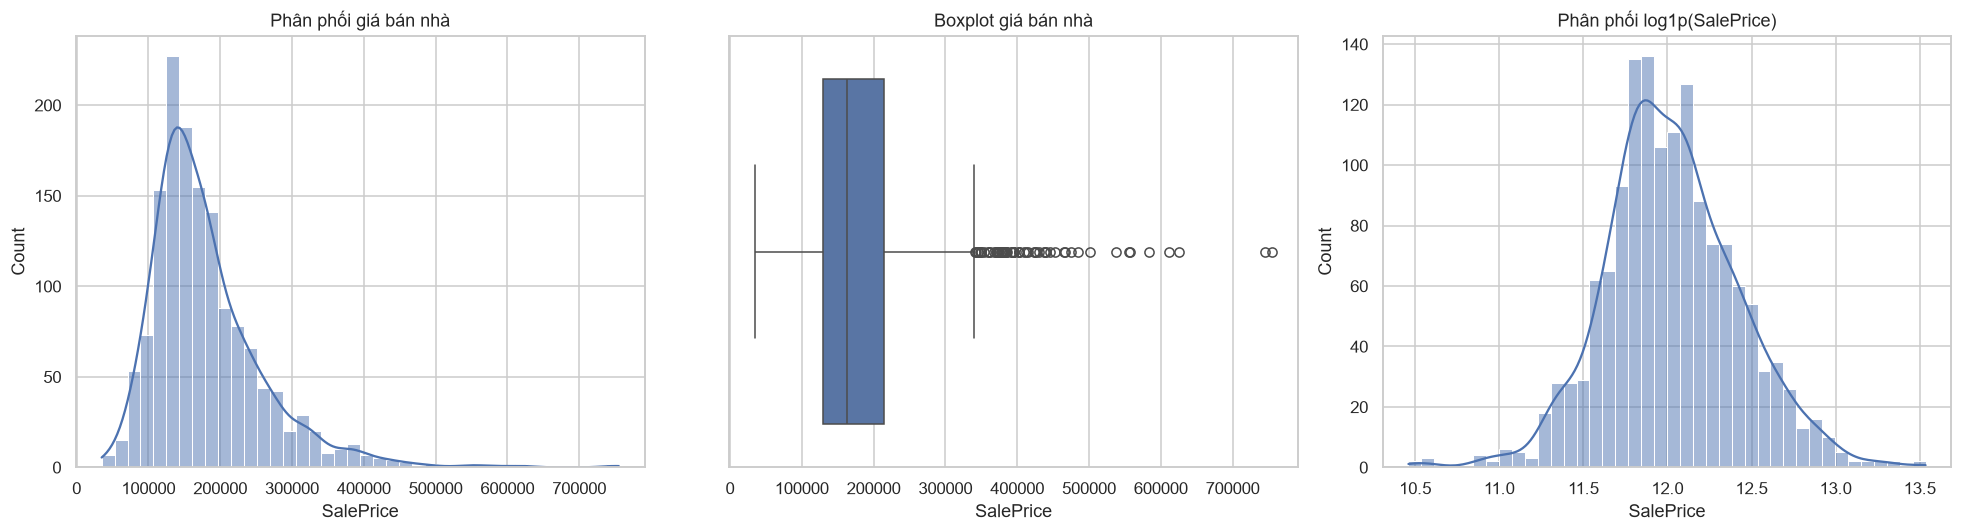

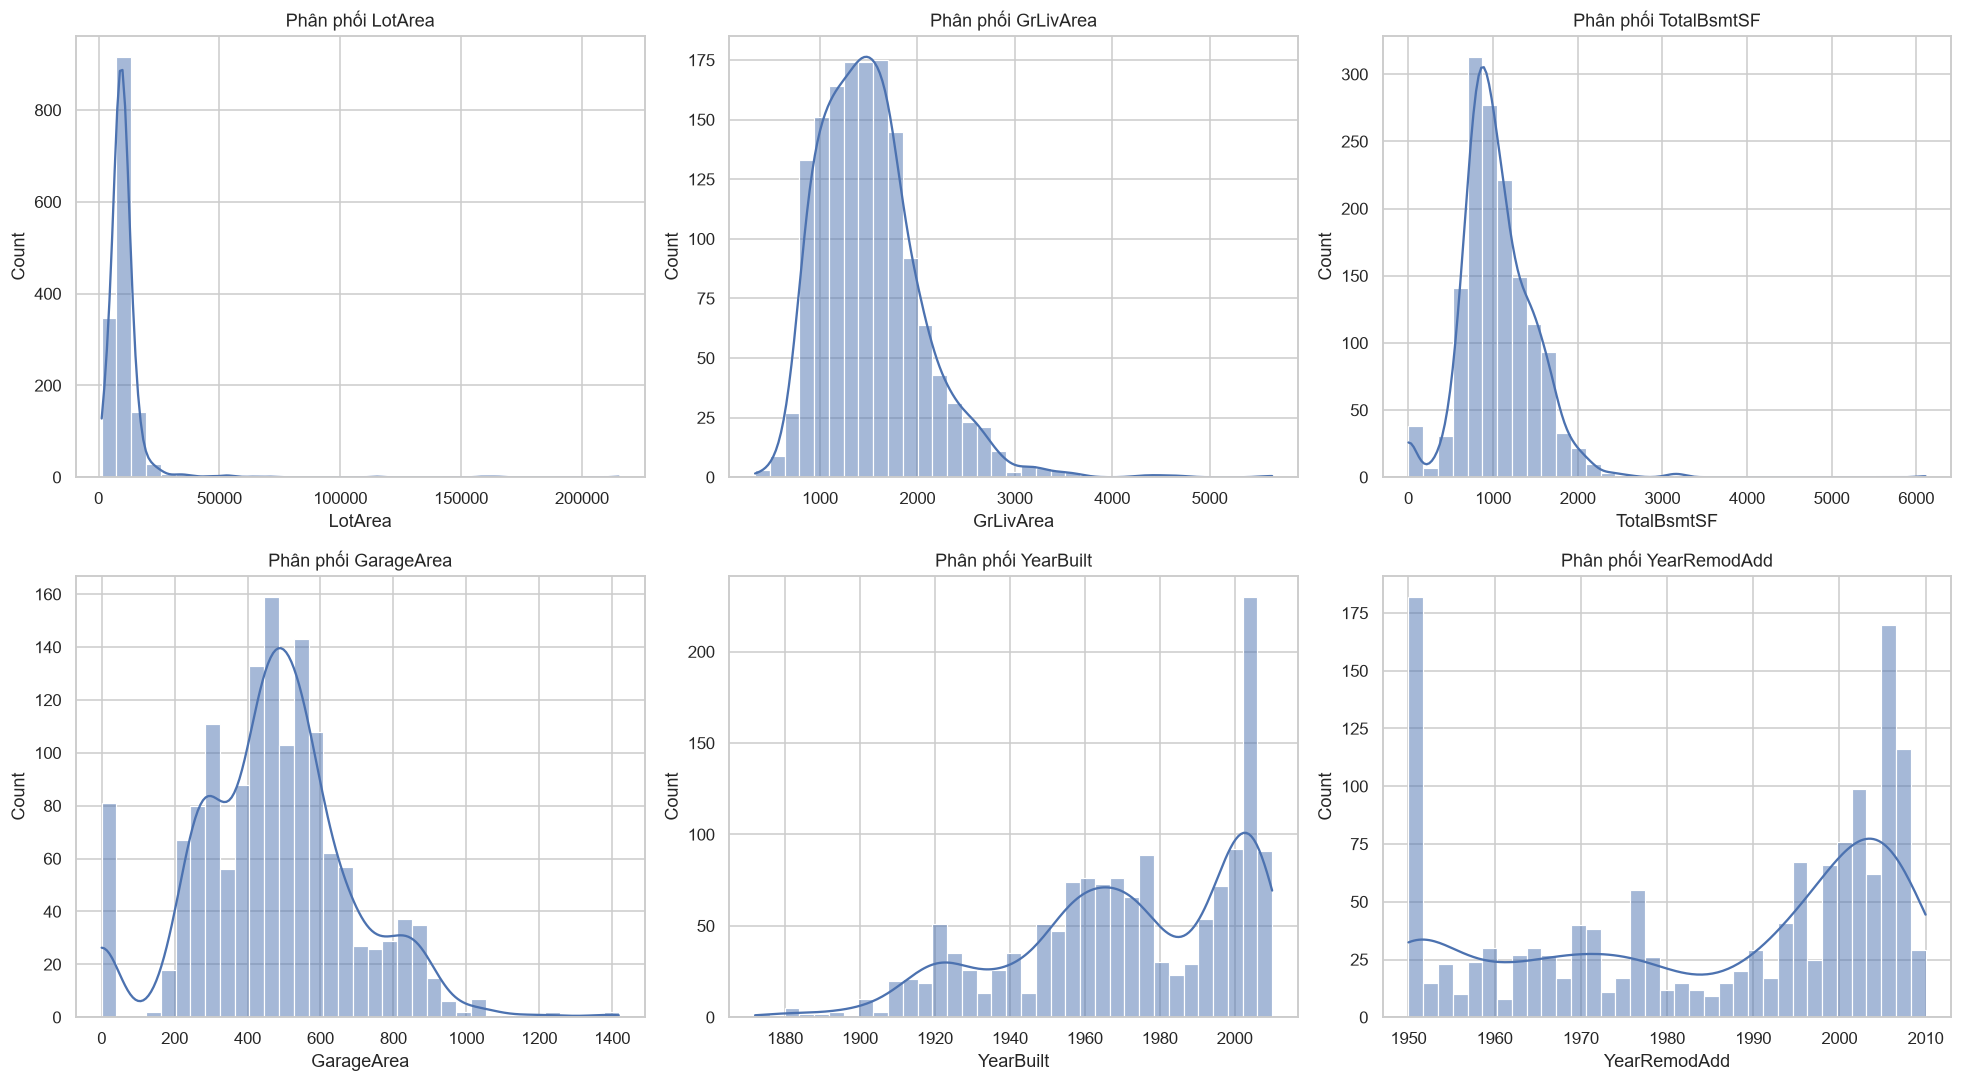


Bảng tần suất: OverallQual


,Số lượng,Tỷ lệ (%)
OverallQual,,
5,397,27.19
6,374,25.62
7,319,21.85
8,168,11.51
4,116,7.95
9,43,2.95
3,20,1.37
10,18,1.23
2,3,0.21



Bảng tần suất: MSSubClass


,Số lượng,Tỷ lệ (%)
MSSubClass,,
20,536,36.71
60,299,20.48
50,144,9.86
120,87,5.96
30,69,4.73
160,63,4.32
70,60,4.11
80,58,3.97
90,52,3.56



Bảng tần suất: Neighborhood


,Số lượng,Tỷ lệ (%)
Neighborhood,,
NAmes,225,15.41
CollgCr,150,10.27
OldTown,113,7.74
Edwards,100,6.85
Somerst,86,5.89
Gilbert,79,5.41
NridgHt,77,5.27
Sawyer,74,5.07
NWAmes,73,5.00



Bảng tần suất: HouseStyle


,Số lượng,Tỷ lệ (%)
HouseStyle,,
1Story,726,49.73
2Story,445,30.48
1.5Fin,154,10.55
SLvl,65,4.45
SFoyer,37,2.53
1.5Unf,14,0.96
2.5Unf,11,0.75
2.5Fin,8,0.55


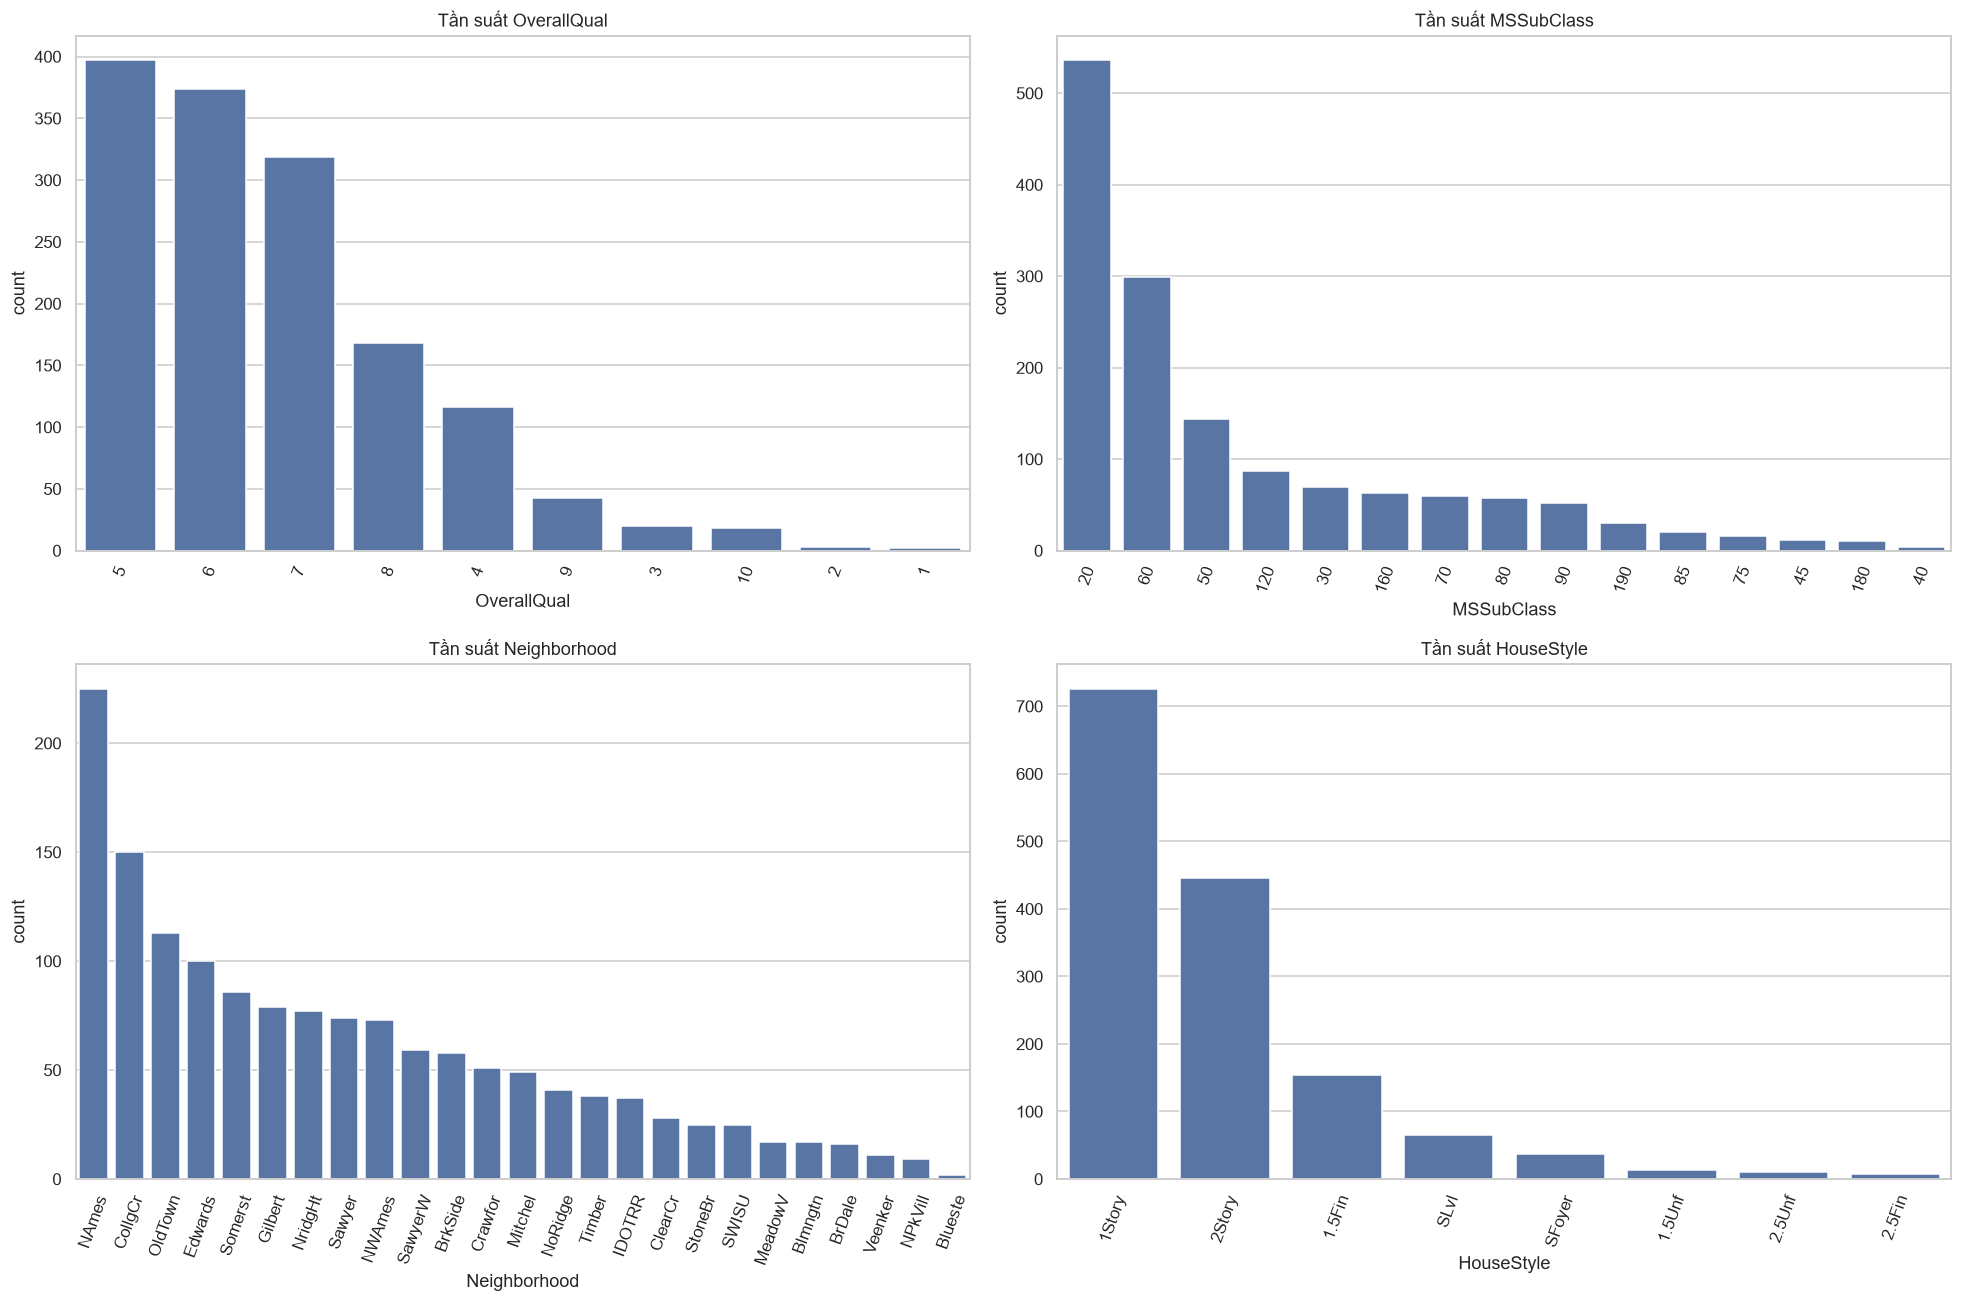

In [20]:
# Thống kê giá nhà
display(train["SalePrice"].describe().to_frame("SalePrice"))

print("Độ lệch SalePrice:", round(train["SalePrice"].skew(), 3))
print("Độ lệch log(SalePrice):", round(np.log1p(train["SalePrice"]).skew(), 3))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.histplot(train["SalePrice"], bins=40, kde=True, ax=axes[0])
axes[0].set_title("Phân phối giá bán nhà")

sns.boxplot(x=train["SalePrice"], ax=axes[1])
axes[1].set_title("Boxplot giá bán nhà")

sns.histplot(np.log1p(train["SalePrice"]), bins=40, kde=True, ax=axes[2])
axes[2].set_title("Phân phối log1p(SalePrice)")

plt.tight_layout()
plt.show()

# Phân phối các biến định lượng tiêu biểu
selected_numeric = ["LotArea", "GrLivArea", "TotalBsmtSF", "GarageArea", "YearBuilt", "YearRemodAdd"]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for col, ax in zip(selected_numeric, axes.ravel()):
    sns.histplot(train[col].dropna(), bins=35, kde=True, ax=ax)
    ax.set_title(f"Phân phối {col}")

plt.tight_layout()
plt.show()

# Phân phối các biến phân loại và thứ bậc
selected_categories = ["OverallQual", "MSSubClass", "Neighborhood", "HouseStyle"]

fig, axes = plt.subplots(2, 2, figsize=(18, 12))
for col, ax in zip(selected_categories, axes.ravel()):
    order = train[col].value_counts().index
    sns.countplot(data=train, x=col, order=order, ax=ax)
    ax.set_title(f"Tần suất {col}")
    ax.tick_params(axis="x", rotation=70)
    
    frequency = train[col].value_counts(dropna=False).to_frame("Số lượng")
    frequency["Tỷ lệ (%)"] = (frequency["Số lượng"] / len(train) * 100).round(2)
    print(f"\nBảng tần suất: {col}")
    display(frequency)

plt.tight_layout()
plt.show()


# PHẦN 6 – Phân tích đa biến
Khảo sát mối liên hệ giữa giá bán và các đặc điểm nhà thông qua tương quan, scatterplot, boxplot, heatmap và pairplot.

===== TOP 15 BIẾN TƯƠNG QUAN MẠNH NHẤT VỚI SALEPRICE =====


,Pearson,Spearman
OverallQual,0.790982,0.809829
GrLivArea,0.708624,0.731310
GarageCars,0.640409,0.690711
GarageArea,0.623431,0.649379
TotalBsmtSF,0.613581,0.602725
1stFlrSF,0.605852,0.575408
FullBath,0.560664,0.635957
TotRmsAbvGrd,0.533723,0.532586
YearBuilt,0.522897,0.652682
YearRemodAdd,0.507101,0.571159


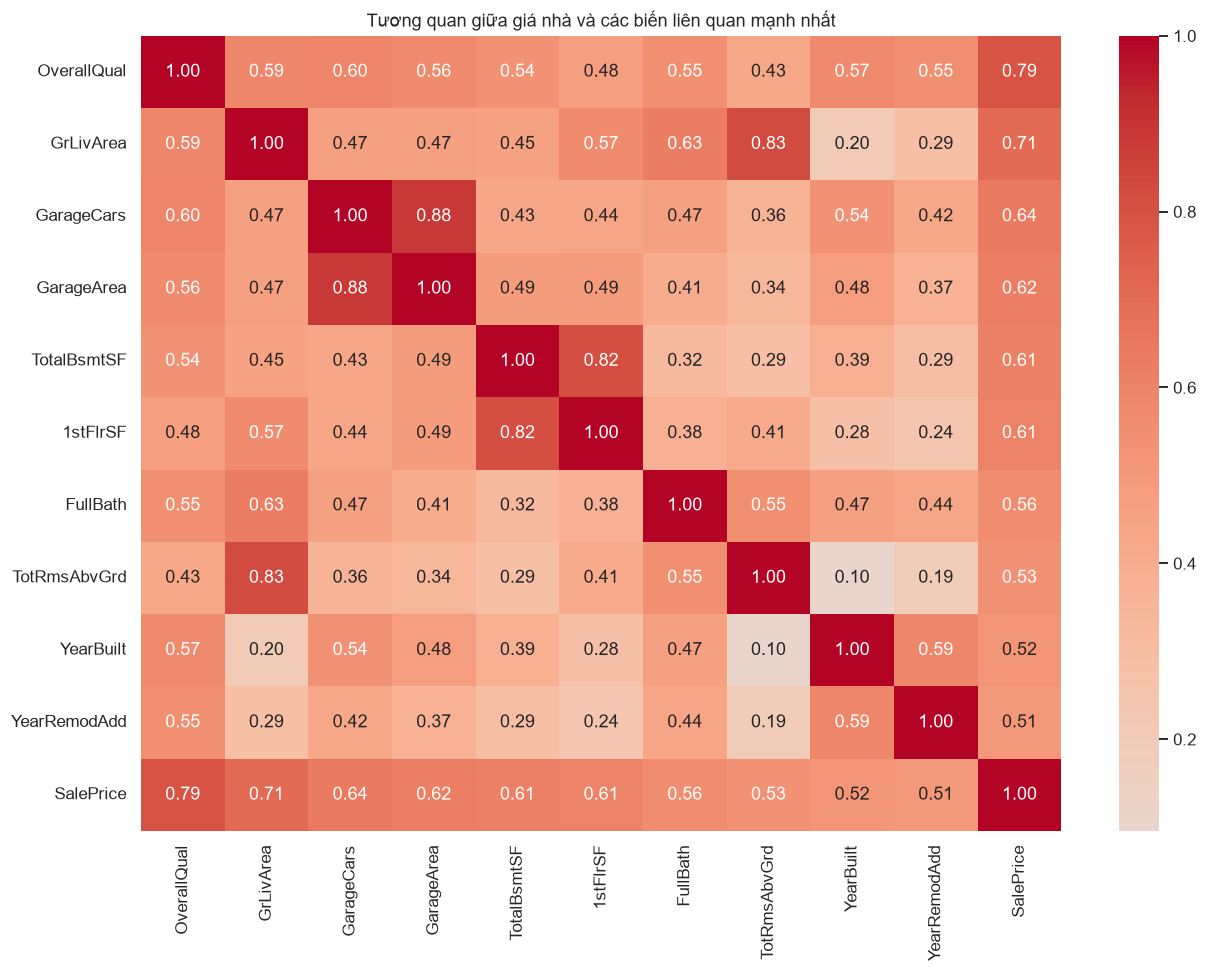

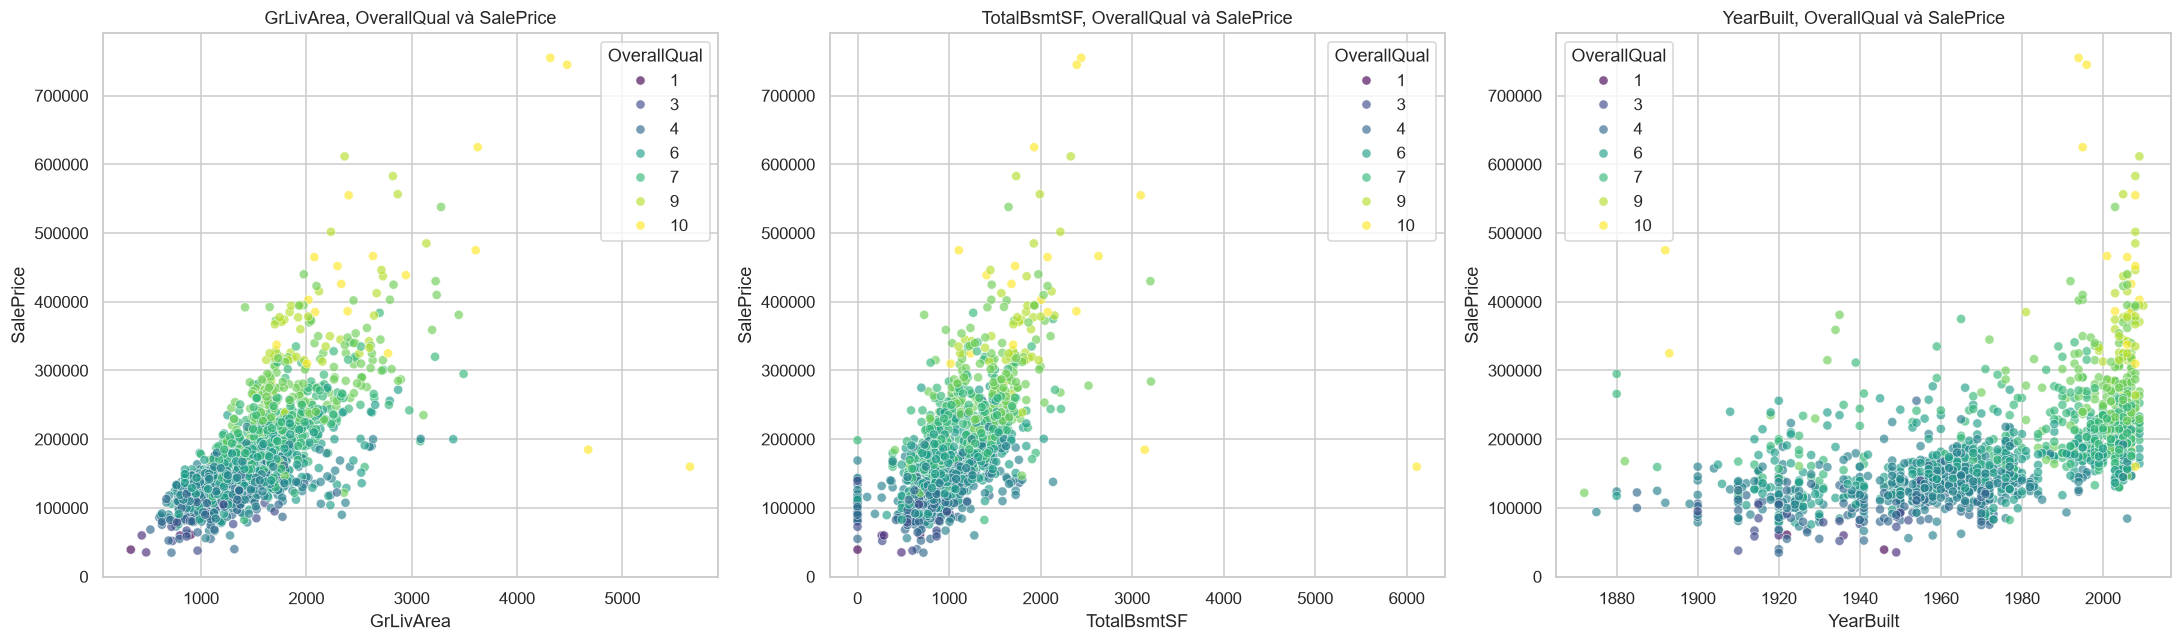

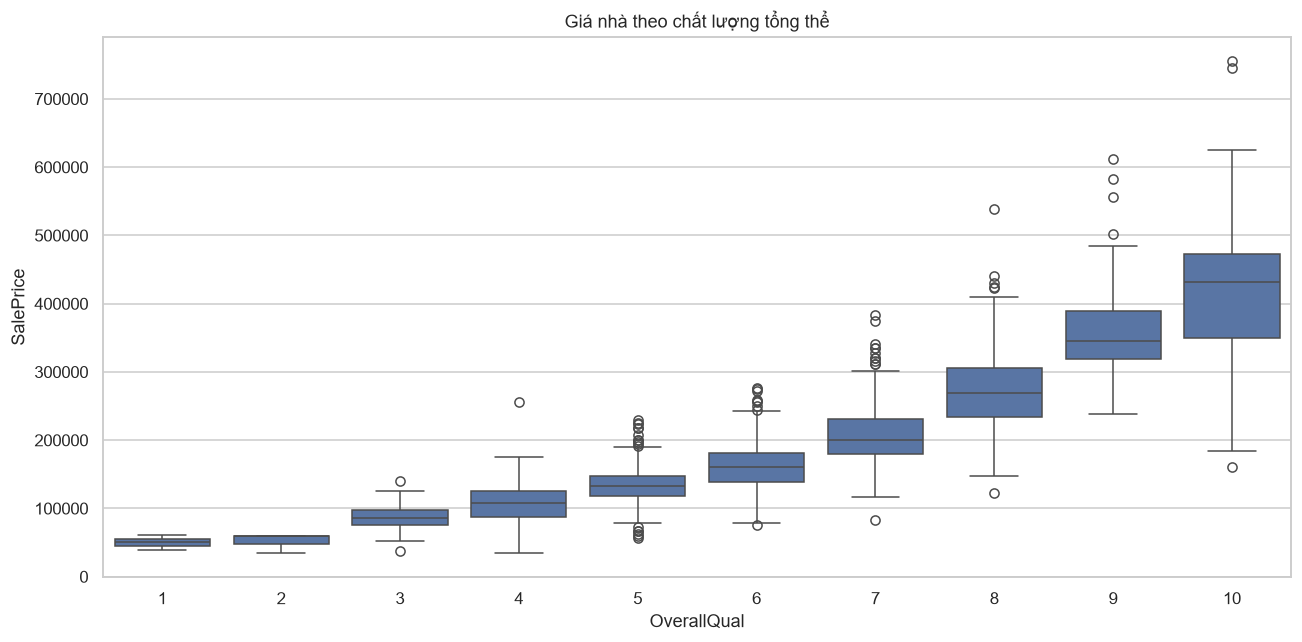

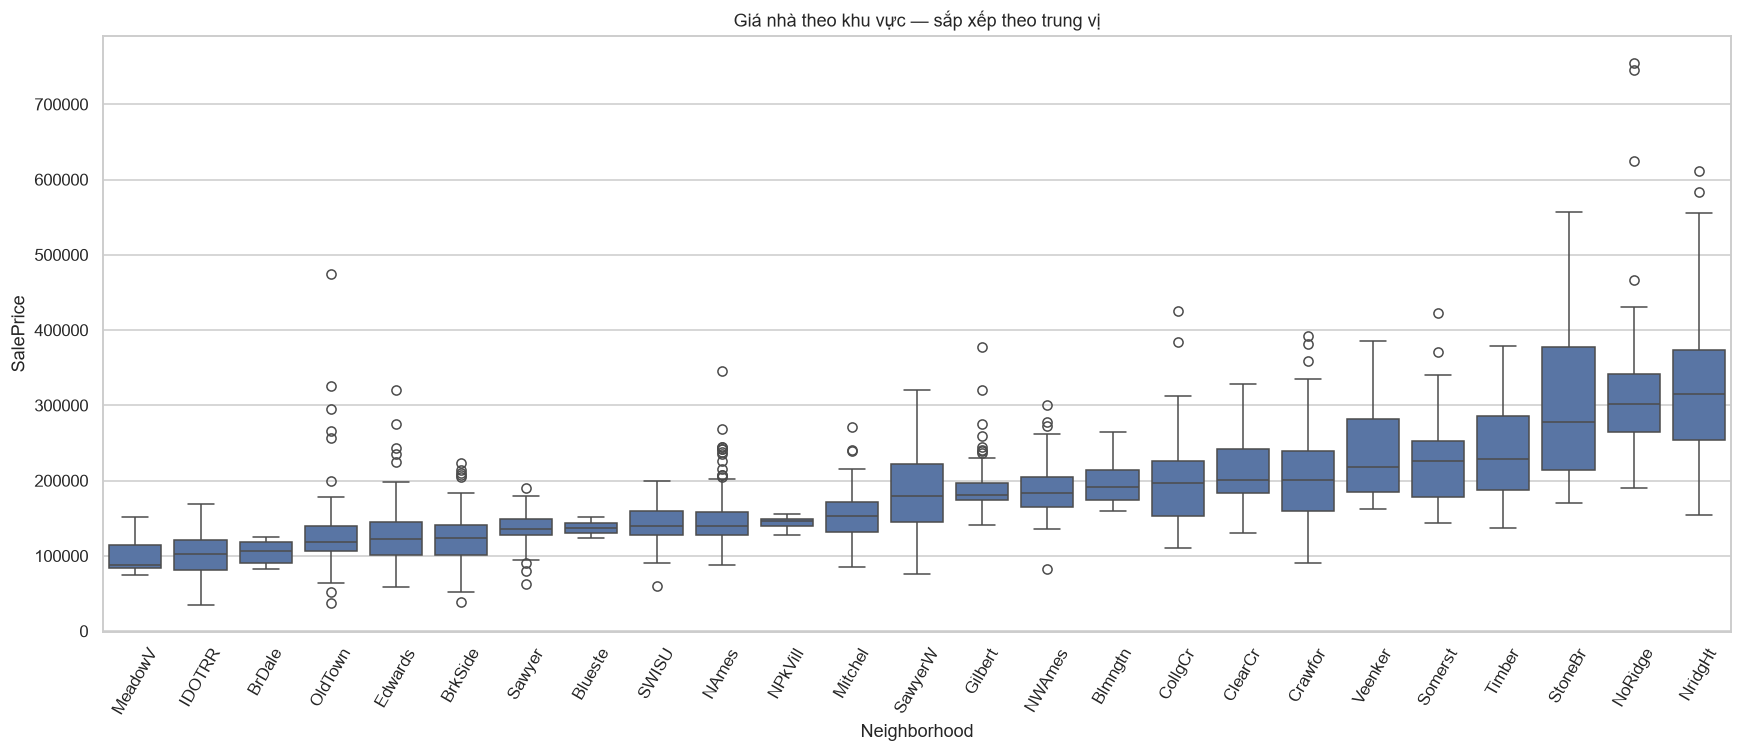

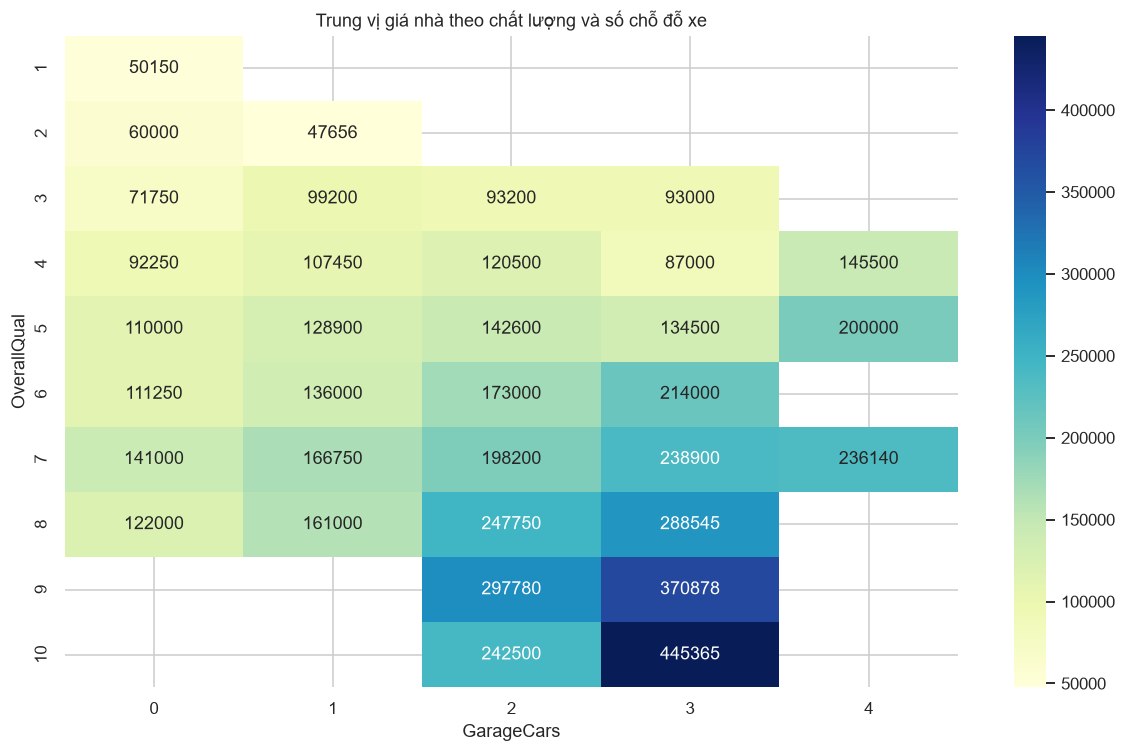

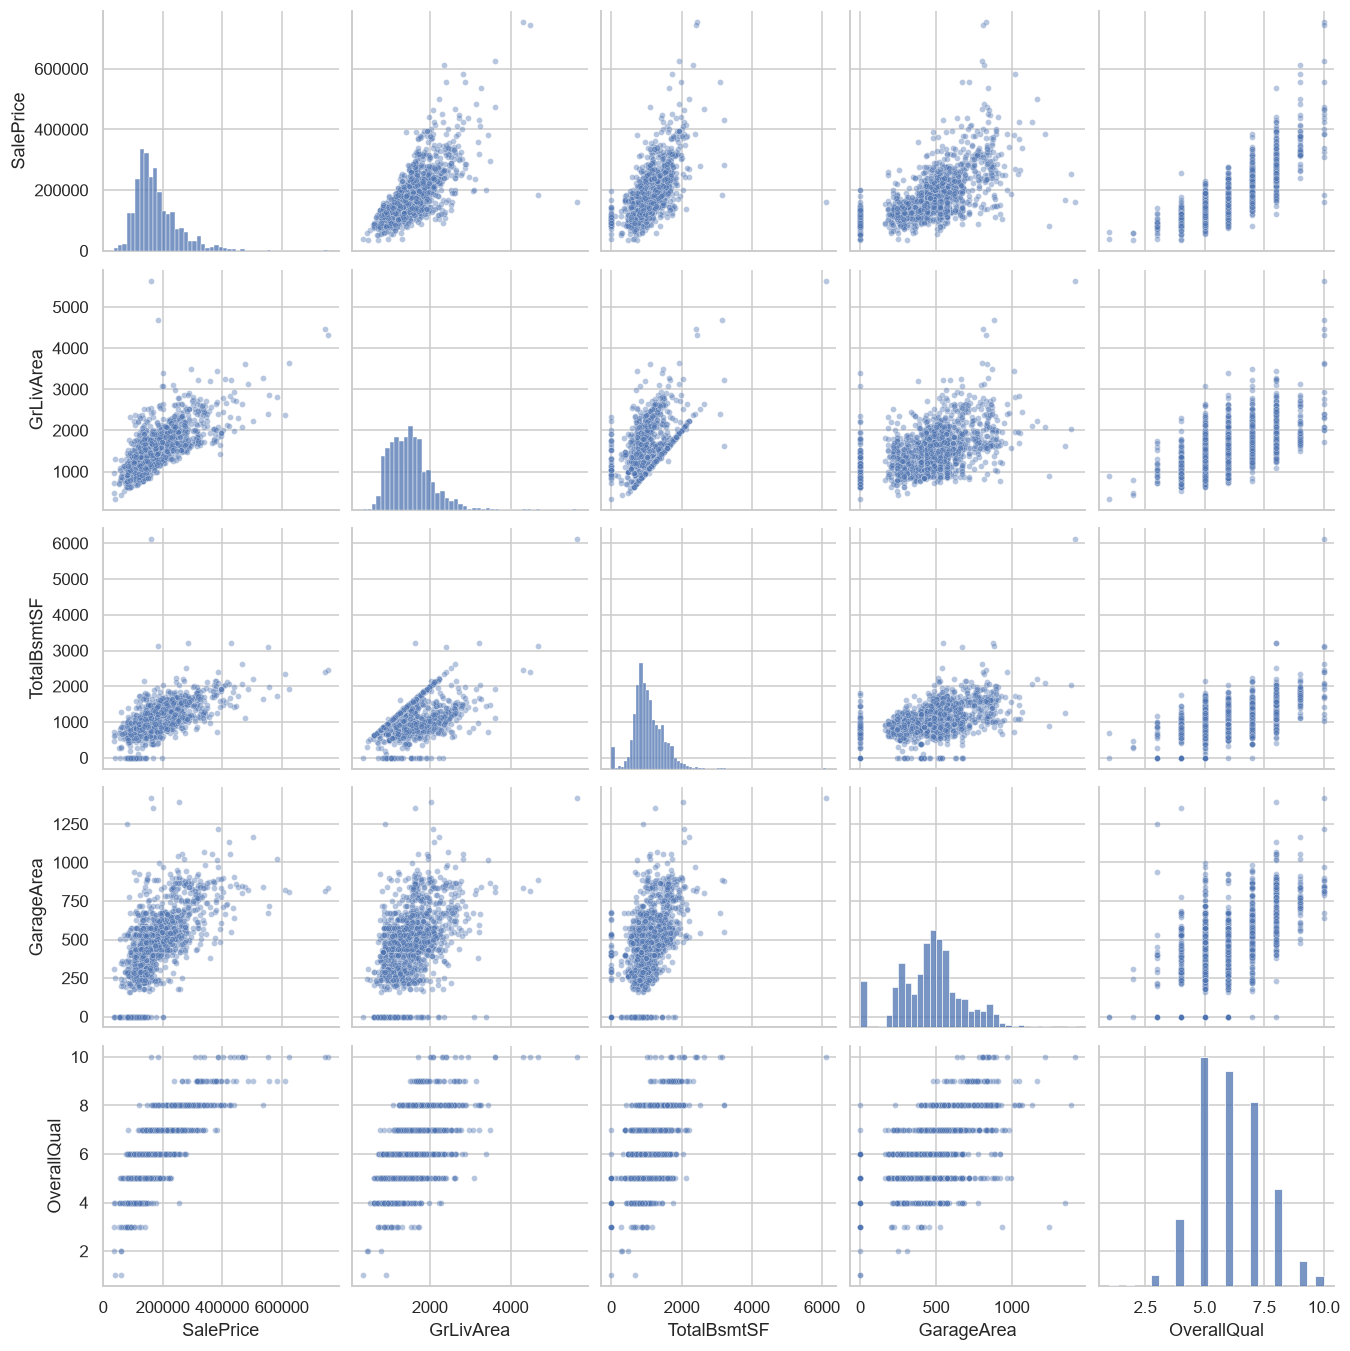

In [21]:
correlation_columns = [
    c for c in train.select_dtypes(include="number").columns
    if c not in ["Id", "MSSubClass", "MoSold"]
]

pearson = train[correlation_columns].corr(method="pearson")
spearman = train[correlation_columns].corr(method="spearman")

target_correlation = pd.DataFrame({
    "Pearson": pearson["SalePrice"],
    "Spearman": spearman["SalePrice"]
}).drop(index="SalePrice")

target_correlation = target_correlation.loc[
    target_correlation["Pearson"].abs().sort_values(ascending=False).index
]
print("===== TOP 15 BIẾN TƯƠNG QUAN MẠNH NHẤT VỚI SALEPRICE =====")
display(target_correlation.head(15))

top_features = target_correlation.head(10).index.tolist()
plt.figure(figsize=(12, 9))
sns.heatmap(train[top_features + ["SalePrice"]].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Tương quan giữa giá nhà và các biến liên quan mạnh nhất")
plt.tight_layout()
plt.show()

# Quan hệ diện tích, tầng hầm và năm xây dựng với giá nhà
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
for col, ax in zip(["GrLivArea", "TotalBsmtSF", "YearBuilt"], axes):
    sns.scatterplot(data=train, x=col, y="SalePrice", hue="OverallQual", palette="viridis", alpha=0.65, ax=ax)
    ax.set_title(f"{col}, OverallQual và SalePrice")
plt.tight_layout()
plt.show()

# Giá nhà theo chất lượng
plt.figure(figsize=(12, 6))
sns.boxplot(data=train, x="OverallQual", y="SalePrice")
plt.title("Giá nhà theo chất lượng tổng thể")
plt.tight_layout()
plt.show()

# Giá nhà theo khu vực
neighborhood_order = train.groupby("Neighborhood")["SalePrice"].median().sort_values().index
plt.figure(figsize=(16, 7))
sns.boxplot(data=train, x="Neighborhood", y="SalePrice", order=neighborhood_order)
plt.xticks(rotation=60)
plt.title("Giá nhà theo khu vực — sắp xếp theo trung vị")
plt.tight_layout()
plt.show()

# Kết hợp hai biến giải thích với giá nhà
price_table = train.pivot_table(values="SalePrice", index="OverallQual", columns="GarageCars", aggfunc="median")
plt.figure(figsize=(11, 7))
sns.heatmap(price_table, annot=True, fmt=".0f", cmap="YlGnBu")
plt.title("Trung vị giá nhà theo chất lượng và số chỗ đỗ xe")
plt.tight_layout()
plt.show()

# Quan hệ giữa nhiều biến cùng lúc (Pairplot)
sns.pairplot(train[["SalePrice", "GrLivArea", "TotalBsmtSF", "GarageArea", "OverallQual"]],
             diag_kind="hist", plot_kws={"alpha": 0.4, "s": 15})
plt.show()


# PHẦN 7 – Kiểm tra độ cân bằng của nhãn mục tiêu
Đánh giá mức độ phân bố số lượng mẫu qua các phân khúc giá bán trong bài toán hồi quy.

===== ĐỘ LỆCH VÀ ĐỘ NHỌN CỦA BIẾN MỤC TIÊU =====


,Chỉ số,Trước biến đổi (SalePrice),Sau biến đổi (log1p),Nhận xét
0,Độ xiên (Skewness),1.883,0.121,Lệch phải mạnh -> Gần như đối xứng hoàn hảo
1,Độ nhọn (Kurtosis),6.540,0.810,Đỉnh nhọn cao -> Đạt chuẩn phân phối chuẩn



===== PHÂN BỐ SỐ LƯỢNG MẪU THEO CÁC PHÂN KHÚC GIÁ =====


,Phân khúc giá,Khoảng giá (USD),Số lượng căn nhà,Tỷ lệ phần trăm (%)
0,Dưới 150 nghìn,"Nhỏ hơn 150,000",619,42.40
1,Từ 150 đến 300 nghìn,"150,000 - 300,000",726,49.73
2,Từ 300 đến 500 nghìn,"300,000 - 500,000",106,7.26
3,Trên 500 nghìn,"Lớn hơn 500,000",9,0.62


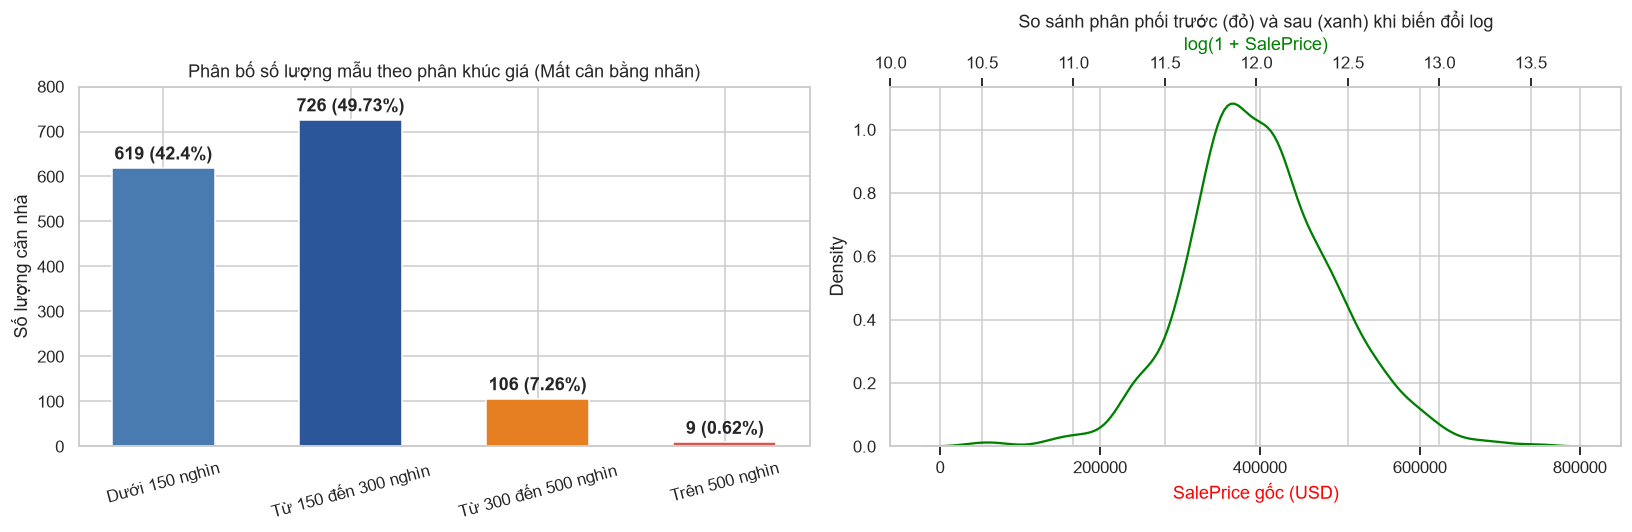

7.5. KẾT LUẬN: Tập dữ liệu mất cân bằng nặng về phân khúc giá (91.23% mẫu dưới 300,000 USD, chỉ 0.62% trên 500,000 USD).
Phép biến đổi log1p giúp chuẩn hóa phân phối về dạng đối xứng, triệt tiêu thiên vị cho mô hình hồi quy.


In [22]:
# 7.1 & 7.2: Đánh giá độ lệch phân bố của biến giá bán SalePrice
sp_skew = train['SalePrice'].skew()
sp_kurt = train['SalePrice'].kurt()
log_sp = np.log1p(train['SalePrice'])
log_skew = log_sp.skew()
log_kurt = log_sp.kurt()

skew_summary = pd.DataFrame({
    'Chỉ số': ['Độ xiên (Skewness)', 'Độ nhọn (Kurtosis)'],
    'Trước biến đổi (SalePrice)': [round(sp_skew, 3), round(sp_kurt, 2)],
    'Sau biến đổi (log1p)': [round(log_skew, 3), round(log_kurt, 2)],
    'Nhận xét': ['Lệch phải mạnh -> Gần như đối xứng hoàn hảo', 'Đỉnh nhọn cao -> Đạt chuẩn phân phối chuẩn']
})
print('===== ĐỘ LỆCH VÀ ĐỘ NHỌN CỦA BIẾN MỤC TIÊU =====')
display(skew_summary)

# 7.3: Thống kê phân bố số lượng mẫu theo các phân khúc giá
bins = [0, 150000, 300000, 500000, float('inf')]
labels = ['Dưới 150 nghìn', 'Từ 150 đến 300 nghìn', 'Từ 300 đến 500 nghìn', 'Trên 500 nghìn']
price_tier = pd.cut(train['SalePrice'], bins=bins, labels=labels)
tier_counts = price_tier.value_counts(sort=False)
tier_pcts = (tier_counts / len(train) * 100).round(2)

tier_df = pd.DataFrame({
    'Phân khúc giá': labels,
    'Khoảng giá (USD)': ['Nhỏ hơn 150,000', '150,000 - 300,000', '300,000 - 500,000', 'Lớn hơn 500,000'],
    'Số lượng căn nhà': tier_counts.values,
    'Tỷ lệ phần trăm (%)': tier_pcts.values
})
print('\n===== PHÂN BỐ SỐ LƯỢNG MẪU THEO CÁC PHÂN KHÚC GIÁ =====')
display(tier_df)

# 7.4: Biểu đồ trực quan hóa độ cân bằng nhãn
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Biểu đồ 1: Số lượng mẫu theo từng phân khúc giá
bars = axes[0].bar(tier_df['Phân khúc giá'], tier_df['Số lượng căn nhà'], color=['#4A7BB0', '#2B579A', '#E67E22', '#D9534F'], width=0.55)
axes[0].set_ylabel('Số lượng căn nhà')
axes[0].set_title('Phân bố số lượng mẫu theo phân khúc giá (Mất cân bằng nhãn)')
axes[0].tick_params(axis='x', rotation=15)
for b, pct in zip(bars, tier_df['Tỷ lệ phần trăm (%)']):
    axes[0].text(b.get_x() + b.get_width()/2.0, b.get_height() + 10, f'{int(b.get_height())} ({pct}%)', ha='center', va='bottom', fontweight='bold')
axes[0].set_ylim(0, 800)

# Biểu đồ 2: So sánh phân phối SalePrice trước và sau khi log
sns.kdeplot(train['SalePrice'], color='red', label=f'Gốc (Skew={sp_skew:.2f})', ax=axes[1])
ax2 = axes[1].twiny()
sns.kdeplot(log_sp, color='green', label=f'Log1p (Skew={log_skew:.2f})', ax=ax2)
axes[1].set_xlabel('SalePrice gốc (USD)', color='red')
ax2.set_xlabel('log(1 + SalePrice)', color='green')
axes[1].set_title('So sánh phân phối trước (đỏ) và sau (xanh) khi biến đổi log')

plt.tight_layout()
plt.show()

print('7.5. KẾT LUẬN: Tập dữ liệu mất cân bằng nặng về phân khúc giá (91.23% mẫu dưới 300,000 USD, chỉ 0.62% trên 500,000 USD).')
print('Phép biến đổi log1p giúp chuẩn hóa phân phối về dạng đối xứng, triệt tiêu thiên vị cho mô hình hồi quy.')


## 5. Xuất kết quả cho các bước sau

In [23]:
miss.join(cls[['phan_loai']]).to_csv('outputs/missing_summary.csv', encoding='utf-8-sig')
audit.to_csv('outputs/anomaly_rules.csv', index=False, encoding='utf-8-sig')
cand.drop(columns=['iso']).to_csv('outputs/outlier_candidates.csv', index=False, encoding='utf-8-sig')
uni.to_csv('outputs/univariate_outliers.csv', encoding='utf-8-sig')
pd.Series([524, 1299], name='Id').to_csv('outputs/ids_to_remove.csv', index=False)
print(sorted(os.listdir('outputs')), '|', len(os.listdir('figures')), 'hình trong figures/')

['anomaly_rules.csv', 'ids_to_remove.csv', 'missing_summary.csv', 'outlier_candidates.csv', 'univariate_outliers.csv'] | 9 hình trong figures/
